# Numerai Classic v6.0 ("Unity") — Deterministic Baselines A, E & Persistence (`NumeraiExtractions` + `BinSnappingEstimator`, `LagReversalEstimator` & `PersistenceEstimator`)

- **Data Loading (`data_utils.load_unity_numerai_data`)**: Resolves and downloads the Unity v6.0 Parquets using the official Kaggle clients (`kagglehub.dataset_download` and `kaggle.api.kaggle_api_extended.KaggleApi`) with `numerapi.NumerAPI` fallback, catching each library's actual exception classes (`KaggleApiHTTPError`, `UnauthenticatedError`, `CredentialError`, `NotFoundError`, `DataCorruptionError`, `BackendError`, `KaggleEnvironmentError`, `ColabEnvironmentError`, `kaggle.rest.ApiException`, `HTTPError`, `OSError`, `ValueError`).
- **Exploratory Data Analysis (`# EDA`)**: Lists available `TARGET_COL` and `feature_set` options from `features.json`, inspects `train_df.head(2)` / `validation_df.head(2)` and `info()`, plots era sizes over time (`groupby(ERA_COL)[TARGET_COL].size()`), overlays feature standard-deviation distributions across Train vs. Validation, and displays the top 10 features correlated with `TARGET_COL`.

---

### 1. Feature Extraction Parameters (`utils.NumeraiExtractions` — `estimator__extractor__*`)
- **`era_col`** (`[ERA_COL]`): Column name containing the sequential weekly time index (`'era'`).
- **`ticker_col`** (`[TICKER_COL]`): Column name containing the security identifier (`'numerai_ticker'`).
- **`target_col`** (`[TARGET_COL, 'target_cyrusd_20', 'target_teager2b_20']`): Target column used when ranking features by target correlation.
- **`year_horizon_filter`** (`[None, (1, 2, 3), (4, 5, 6), (7, 8, 9)]`): Restricts `fit()` variance and correlation estimation to specific 52-week training year buckets `(era - 1) // 52 + 1` (`None` uses all training years; never exposed as a model feature).
- **`variance_threshold`** (`[None, 0.02, 0.05, 0.10]`): Drops near-constant features whose training variance is $\le$ threshold via `sklearn.feature_selection.VarianceThreshold` (`None` keeps all features).
- **`correlation_method`** (`[None, 'pandas_mean', 'numerai_mean', 'pearson', 'spearman']`):
  - `None`: Skips correlation ranking and keeps original column order.
  - `'pandas_mean'`: Computes per-era Pearson correlation (`era_df.corrwith(era_target)`) and averages across eras.
  - `'numerai_mean'`: Computes official per-era `numerai_tools.scoring.numerai_corr` and averages across eras.
  - `'pearson'`: Global pooled Pearson correlation (`r_regression`) across all rows.
  - `'spearman'`: Global pooled Spearman rank correlation across all rows.
- **`abs_corr`** (`[True, False]`): `True` ranks features by $|\text{corr}|$ (strongest magnitude in either direction); `False` ranks by signed $\text{corr}$ (positive only first).
- **`top_k`** (`[None, 10, 20, 40]`): Keeps only the top $K$ highest-ranked features from the extractor (`None` keeps all features).
- **`feature_selection_percentile`** (`[None, 25.0, 50.0, 75.0, 100.0]`): Keeps the top percentage of ranked features (`None` keeps all features).
- **`sparse_selector`** (`[None, 'lasso', 'elasticnet']`) & **`sparse_alpha`** (`[0.001, 0.01, 0.1]` / `Real(1e-4, 1e-1, prior='log-uniform')`): Optional multivariate sparse feature selection via `sklearn.feature_selection.SelectFromModel` with `Lasso` or `ElasticNet` fitted strictly inside `fit()` (`None` disables).
- **`pca_n_components`** (`[None, 10, 20, 40]` / `0.90`): Optional `sklearn.decomposition.PCA` compression fitted strictly inside `fit()` and quantized to `0..4` `int8` bins in `transform()` to reduce feature exposure without dropping features (`None` disables).
- **`quantize_scope`** (`['era', 'train_fit', 'global']`) & **`quantize_strategy`** (`['zscore', 'quantile']`): Controls how continuous derived features are quantized into `0..4` `int8` bins (`'era'` = leak-free within-era cross-sectional quantization; `'train_fit'` = frozen `StandardScaler` fitted strictly on training data in `fit()`; `'global'` = legacy full-array quantization; `'zscore'` = z-score rounding vs. `'quantile'` = `KBinsDiscretizer` quantile edges).
- **`sequence_top_n`** (`[4, 2, 8]`): Number of top-ranked features expanded by rolling-era, lag-diff, and per-ticker sequence extractors.
- **`missing_fill_value`** (`[2.0, 0.0, 4.0, 'mean', 'median', 'era_mean', 'era_median']`):
  - `2.0`, `0.0`, `4.0`, `'mean'`, `'median'`: Imputes missing values via `sklearn.impute.SimpleImputer` (`2.0` is the neutral middle bin of Numerai's `0..4` scale).
  - `'era_mean'` / `'era_median'`: Fills missing values with each feature's within-era cross-sectional mean or median.
- **`feature_groups`** (`unity_feature_groups` on `NumeraiExtractions`, `None` if no thematic groups exist in `feature_metadata['feature_sets']`; omitted from CV search spaces to prevent console log bloat) & **`basic_group_stats`** (`[None, 'mean', 'std', 'skew', 'mean|std', 'mean|skew', 'std|skew', 'mean|std|skew']`): Computes leak-free row-wise summary statistics (`mean`, `std`, `skew` quantized to `0..4` bins) across real Unity v6.0 feature groups or built-in thematic prefixes (`None` disables).
- **`fourier_period_eras`** (`[52, 26, 13]`): Cycle length in eras (52 = annual, 26 = semi-annual, 13 = quarterly) used by `fourier_order`.
- **`fourier_order`** (`[None, 1, 2, 3]`): Sole cyclical seasonality encoding — adds smooth $\sin(2\pi k \cdot \text{era} / P)$ and $\cos(2\pi k \cdot \text{era} / P)$ harmonics for $k=1..\text{fourier\_order}$ quantized to `0..4` bins (`None` disables).
- **`include_rolling_era`** (`[False, True]`) & **`rolling_era_windows`** (`[(4, 12), (2, 6, 12), (4, 8, 16)]`): When `include_rolling_era=True`, computes causal rolling era means over each window length $W$ in `rolling_era_windows` for the top correlated features, quantized to `0..4` bins.
- **`include_lag_diff`** (`[False, True]`) & **`era_lag_scales`** (`[(1, 2, 4), (1, 2, 4, 8), (2, 4, 8)]`): When `include_lag_diff=True`, computes causal era-to-era lag differences ($\bar{x}_e - \bar{x}_{e-k}$) for each lag step $k$ in `era_lag_scales`, quantized to `0..4` bins.
- **`ticker_features`** (`[None, 'rolling_mean', 'momentum_diff', 'weeks_since_high', 'rolling_rank', 'weeks_since_change', 'expanding_stats', 'raw_lags', 'rolling_mean|momentum_diff', 'rolling_mean|momentum_diff|rolling_rank', 'expanding_stats|raw_lags', 'rolling_mean|momentum_diff|weeks_since_high|rolling_rank|weeks_since_change|expanding_stats|raw_lags']`), **`ticker_windows`** (`[(4, 12), (2, 6, 12)]`), & **`ticker_lag_steps`** (`[None, (1, 2), (1, 2, 4)]`): Computes causal per-ticker time-series features (`rolling_mean`, `momentum_diff`, vectorized `weeks_since_high`, `rolling_rank`, vectorized `weeks_since_change`, `expanding_stats` [`expanding().mean()/min()/max()`], and `raw_lags` [`shift(k)` for $k \in$ `ticker_lag_steps`]) grouped strictly by `numerai_ticker` sorted chronologically by `era` (`None` disables).
- **`era_dispersion_features`** (`[None, 'mean', 'std', 'extreme_frac', 'mean|std', 'mean|extreme_frac', 'std|extreme_frac', 'mean|std|extreme_frac']`): Adds per-row cross-sectional mean (`'mean'`), standard deviation (`'std'`), and fraction of extreme `0`/`4` bins (`'extreme_frac'`) across selected features (`None` disables).

---

### 2. Shared Parent Estimator Parameters (`baseline_utils.BaseNumeraiEstimator` — `estimator__*`)
- **`correlation_method`** (`[None, 'pandas_mean', 'numerai_mean', 'pearson', 'spearman']`): How the estimator scores and weights post-extraction features against `TARGET_COL`.
- **`abs_corr`** (`[True, False]`): `True` selects top features by $|\text{corr}|$; `False` selects by signed $\text{corr}$.
- **`top_k`** (`[None, 10, 20, 40]`): Number of top post-extraction features used by the estimator (`None` uses all extracted features).
- **`era_weighting`** (`[None, 'equal_era', 'recency_linear', 'recency_exp']`):
  - `None`: Equal weight per row.
  - `'equal_era'`: Equal total weight per era ($1 / N_{\text{era}}$) so large eras do not dominate.
  - `'recency_linear'`: Linearly increases era weight from oldest ($0.5$) to newest ($1.5$).
  - `'recency_exp'`: Exponentially decays older eras by $\exp(-\text{recency\_decay} \cdot (e_{\max} - e))$.
- **`recency_decay`** (`Real(0.001, 0.020)`): Exponential decay rate per era when `era_weighting='recency_exp'`.
- **`prediction_transform`** (`[None, 'era_zscore', 'era_rank']`):
  - `None`: Returns raw model predictions.
  - `'era_zscore'`: Standardizes predictions to zero mean and unit variance within each era.
  - `'era_rank'`: Converts predictions to `[0, 1]` percentile ranks within each era.
- **`bias_correction`** (`[None, 'mean_residual']`): When `'mean_residual'`, records `mean(y_train - y_hat_train)` in `fit()` and adds it to predictions in `predict()` (`None` disables).

---

### 3. Child Baseline Estimator Parameters (`BinSnappingEstimator`, `LagReversalEstimator` & `PersistenceEstimator`)
- **Baseline A — `BinSnappingEstimator` (Map Matching Lookup Table)**:
  - **`n_bins`** (`[5, 3, 7]`): Number of discrete integer bins per feature (`5` matches Numerai's `0..4` bins).
  - **`smoothing`** (`[0.0, 25.0, 50.0, 100.0]` / `Real(0.0, 100.0)`): Empirical-Bayes shrinkage weight pulling sparse bin averages toward the global target mean ($\frac{\sum y + m \cdot \bar{y}}{N + m}$).
  - **`agg_mode`** (`['mean', 'corr_weighted']`): `'mean'` averages snapped bin predictions equally across selected features; `'corr_weighted'` weights each feature's bin lookup by $|\text{corr}_j|$.
- **Baseline E — `LagReversalEstimator` (Era Autocorrelation / PACF Sign & Shrinkage Rule)**:
  - **`lag`** (`[1, 2, 4, 6]` / `Integer(1, 6)`): Number of era steps $k$ used to compute each feature's era-level lag-$k$ serial dependence.
  - **`acf_mode`** (`['feature_mean', 'feature_corr']`): `'feature_mean'` computes lag-$k$ dependence on each feature's per-era mean series; `'feature_corr'` computes lag-$k$ dependence on each feature's per-era target-correlation series.
  - **`acf_metric`** (`['acf', 'pacf']`): `'acf'` uses lag-$k$ autocorrelation; `'pacf'` uses lag-$k$ partial autocorrelation (`statsmodels.tsa.stattools.pacf`).
  - **`acf_detrend`** (`[None, 'linear', 'constant']`): Detrends the era series via `scipy.signal.detrend` before computing $\text{ACF}(k)$/$	ext{PACF}(k)$ (`None` = raw series, `'linear'` = removes linear time trend, `'constant'` = subtracts series mean).
  - **`acf_threshold`** (`[-0.05, 0.0, 0.05]` / `Real(-0.20, 0.20)`): Cutoff threshold $\tau$ for sign inversion or continuous shrinkage.
  - **`sign_mode`** (`['hard', 'soft_threshold', 'tanh']`): `'hard'` applies $\pm 1$ sign flip around `acf_threshold`; `'soft_threshold'` applies continuous soft-thresholded shrinkage; `'tanh'` applies smooth $\tanh((\text{acf} - \tau)/0.05)$ shrinkage.
  - **`center_features`** (`[True, False]`): `True` centers each feature by its training mean before applying the signed correlation weights; `False` multiplies raw bin values.
- **Brownlee Persistence Baseline — `PersistenceEstimator` (Decoupled Per-Ticker Target Persistence / Zero-Rule)**:
  - **`ticker_col`** (`[TICKER_COL]`): Security identifier column (`'numerai_ticker'`).
  - **`persistence_mode`** (`['last', 'expanding_mean', None]`): `'last'` predicts each ticker's most recent settled training target; `'expanding_mean'` predicts each ticker's historical training target mean; `None` falls back to Brownlee's Zero-Rule baseline (global training target mean).
  - **`persistence_lag`** (`[4, 1, 2, 8, None]`): Minimum era lag required before a training target is treated as settled (`4` for 20-day targets; `None` uses all available training history).
  - **`smoothing`** (`[0.0, 10.0, 25.0, 50.0]` / `Real(0.0, 100.0)`): Shrinkage pulling ticker target history toward the global training mean (`0.0` or `None` = no shrinkage).

---

- **Evaluation (`utils.evaluate_numerai_predictions`)**: Reports official `numerai_tools.scoring.numerai_corr`, per-era `Spearman Correlation`, `Average Payout` (`(corrs / 0.2).clip(-1, 1)`), `Sharpe Ratio` (`corrs.mean() / corrs.std()`), `Mean Absolute Error (MAE)`, `Forecast Bias` (`mean(y_true - y_pred)`), `Directional Hit Rate` (sign agreement vs. `0.5`), `Era CORR Lag-1 ACF`, `Ljung-Box p-value` (`acorr_ljungbox`), `ARCH-LM p-value` (`het_arch`), `ADF Stationarity p-value` (`adfuller`), `Skewness`, `Excess Kurtosis`, `Jarque-Bera p-value`, `Max Drawdown`, and validation `Feature Exposure`.

In [1]:
import gc
import os
import sys
import json
import time
import warnings
import importlib
from pathlib import Path
from datetime import datetime

python_env_dir = Path(sys.executable).parent
library_bin_dir = python_env_dir / 'Library' / 'bin'
if library_bin_dir.is_dir() and str(library_bin_dir) not in os.environ.get('PATH', ''):
    os.environ['PATH'] = str(library_bin_dir) + os.pathsep + str(python_env_dir) + os.pathsep + os.environ.get('PATH', '')

import numpy as np
import pandas as pd
try:
    import matplotlib.pyplot as plt
except ImportError:
    plt = None
try:
    import seaborn as sns
except ImportError:
    sns = None
from IPython.display import display

warnings.filterwarnings('ignore')

# Local, Kaggle (/kaggle/input, /kaggle/usr/lib, /kaggle/working), & nested dataset path routing
current_dir = os.getcwd()
workspace_root = current_dir
if os.path.basename(current_dir).lower() == 'notebooks':
    workspace_root = os.path.dirname(current_dir)

src_path = os.path.join(workspace_root, 'src')
if workspace_root not in sys.path:
    sys.path.insert(0, workspace_root)
if os.path.isdir(src_path) and src_path not in sys.path:
    sys.path.insert(0, src_path)

module_search_roots = [
    Path(workspace_root),
    Path('/kaggle/working'),
    Path('/kaggle/usr/lib'),
    Path('/kaggle/input'),
]
for search_root in module_search_roots:
    if not search_root.is_dir():
        continue
    for target_file in ('afml_utils.py', 'data_utils.py', 'utils.py', 'baseline_utils.py'):
        for found_path in search_root.rglob(target_file):
            parent_dir = str(found_path.parent)
            if parent_dir not in sys.path:
                sys.path.insert(0, parent_dir)

from pandas.plotting import autocorrelation_plot
from scipy.stats import spearmanr
from joblib import Parallel, delayed
from sklearn.base import clone
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.pipeline import Pipeline
from statsmodels.graphics.gofplots import qqplot

from numerai_tools.scoring import numerai_corr

try:
    import skopt
    from skopt import BayesSearchCV
    from skopt.space import Categorical, Integer, Real
    SKOPT_AVAILABLE = True
except ImportError:
    BayesSearchCV = None
    Categorical = Integer = Real = None
    SKOPT_AVAILABLE = False

try:
    import wandb
except ImportError:
    wandb = None

try:
    import afml_utils
    import data_utils
    import utils
    import baseline_utils
except ModuleNotFoundError as import_err:
    mounted_kaggle_inputs = [str(p) for p in sorted(Path('/kaggle/input').iterdir())] if Path('/kaggle/input').is_dir() else []
    raise ModuleNotFoundError(
        f"{import_err}. Could not locate data_utils.py / utils.py / baseline_utils.py in "
        f"workspace_root={workspace_root}, /kaggle/working, /kaggle/usr/lib, or /kaggle/input "
        f"(mounted inputs: {mounted_kaggle_inputs}). "
        "On Kaggle, attach a Dataset or Utility Script containing src/data_utils.py, src/utils.py, and src/baseline_utils.py."
    ) from import_err
importlib.reload(afml_utils)
importlib.reload(data_utils)
importlib.reload(utils)
importlib.reload(baseline_utils)
from data_utils import (
    compute_per_ticker_timeseries_features,
    discover_and_fetch_v6_meta_or_benchmark,
    load_unity_numerai_data,
    load_unity_numerai_data_cached,
)
from utils import (
    NumeraiExtractions,
    build_experiment_setup,
    build_conditional_bayesian_spaces,
    build_quick_results_df,
    candidate_score,
    compute_r1399_churn_retention,
    compute_versioned_candidate_score,
    make_candidate_scorer,
    compute_eda_era_stationarity,
    compute_era_error_envelope,
    configure_error_binning,
    compute_feature_exposure,
    compute_feature_target_correlations,
    compute_per_era_mmc,
    compute_per_era_numerai_corr,
    compute_per_era_spearman_corr,
    deduplicate_param_grid,
    drop_constant_dims,
    evaluate_numerai_predictions,
    export_diagnostics_predictions,
    plot_era_error_envelope,
    plot_residual_diagnostics,
    plot_stake_pnl_dashboard,
    plot_stake_pnl_monte_carlo,
    prepare_bayesian_space,
    quantize_to_5bins,
    reset_cv_metric_log,
    run_numereval_diagnostics,
    sharpe_ratio,
    build_live_staking_scenarios_df,
    compute_deflated_sharpe_ratio,
    compute_probabilistic_sharpe_ratio,
    simulate_live_staking_scenarios,
    simulate_stake_pnl,
    simulate_stake_pnl_monte_carlo,
    walk_forward_predict,
    CombinatorialPurgedEraCV,
    PurgedEraKFold,
    build_era_cv_splits,
    compute_clustered_mda,
    compute_drawdown_and_tuw,
    compute_hhi_concentration,
    compute_lo_adjusted_sharpe,
    compute_min_track_record_length,
    compute_pbo_cscv,
    compute_per_era_fnc,
    compute_strategy_risk,
    neutralize_predictions,
    purge_train_before_validation,
    summarize_afml_backtest_diagnostics,
    build_compact_afml_reference_table,
    build_diagnostics_summary_table,
    build_executive_scorecard_tables,
    display_compact_dataframe,
    export_winner_scorecard_json,
    plot_afml_backtest_story,
    plot_cumulative_validation_corr,
    plot_rolling_validation_corr,
    plot_top2_residuals_vs_actual,
    build_afml_diagnostics_df,
    strip_validation_predictions,
)
from baseline_utils import (
    BaseNumeraiEstimator,
    BinSnappingEstimator,
    LagReversalEstimator,
    PersistenceEstimator,
    clear_extraction_cache,
    configure_extraction_cache,
    display_baseline_interpretability,
    display_top_cv_candidates,
    extract_baseline_interpretability,
    extract_cv_analysis_artifacts,
    run_baseline,
)

print('Imports loaded successfully')
print(f'workspace_root={workspace_root} | SKOPT_AVAILABLE={SKOPT_AVAILABLE}')

Imports loaded successfully
workspace_root=/kaggle/working | SKOPT_AVAILABLE=True


# Setup

In [2]:
# --- Experiment Knobs (only things you actually change) ---
TARGET_COL = 'target'          # Training target (auto-sets horizon & embargo)
feature_set = 'all'          # 'small', 'medium', or 'all'
era_stride = 'auto'           # 'auto' (matches target horizon: 12 for 60d, 4 for 20d) or explicit int (1, 2, 4, 12)

baseline_mode = 'persistence'          # 'baseline_a', 'baseline_e', 'persistence', 'both', 'all'
search_mode = 'bayes'          # 'grid' or 'bayes'
score_version = 'v1_skepta'    # 'v0_default', 'v1_skepta', or 'v2_skepta_mmc'
eval_mode = 'both'             # 'static', 'walk_forward', or 'both'
cv_strategy = 'timeseries'   # 'timeseries', 'purged_kfold' (AFML Ch. 7), or 'cpcv' (AFML Ch. 12)
n_splits = 337
cv_split = 0.8                 # Chronological CV train/test split ratio (used when n_splits == 1)
downsample_mode = 'recent'         # None, 'within_era', 'recent', 'earliest', 'uniform', or 'random_eras'
downsample_frac = 1.0          # Fraction of strided training data to keep in (0.0, 1.0]
val_downsample_mode = 'recent'     # Validation: None (100%), 'same', 'within_era', 'recent', 'earliest', 'uniform', or 'random_eras'
val_downsample_frac = 1.0             # Fraction of validation data to keep in (0.0, 1.0] (None mirrors downsample_frac)
n_iter = 1
n_jobs = 1                    # Use 1 for feature_set='all' to save RAM
save_results = True
error_bin_mode = 'pct'         # 'pct' (% error + zero-target tol) or 'abs' (raw residual bins)

setup_cfg = build_experiment_setup(    target_col=TARGET_COL,

                                   
                                   
    feature_set=feature_set,
    era_stride=era_stride,
    model_tag='baselines_ae',
    baseline_mode=baseline_mode,
    search_mode=search_mode,
    score_version=score_version,
    eval_mode=eval_mode,
    cv_strategy=cv_strategy,
    n_splits=n_splits,
    cv_split=cv_split,
    downsample_mode=downsample_mode,
    downsample_frac=downsample_frac,
    val_downsample_mode=val_downsample_mode,
    val_downsample_frac=val_downsample_frac,
    n_iter=n_iter,
    n_jobs=n_jobs,
    save_results=save_results,
    error_bin_mode=error_bin_mode,
    workspace_root=workspace_root,
)
globals().update(setup_cfg)

Experiment: numerai_v6.0_all_eras_stride12_baselines_ae | baseline_mode=persistence | search_mode=bayes | cv_strategy=timeseries (cv_split=0.8) | ERA_COL=era | TARGET_COL=target | era_stride=12 (auto-matched to horizon=12) | horizon=12 | embargo=1


# Prep

In [3]:
_prep_t0 = time.perf_counter()
train_df, validation_df, feature_columns, feature_metadata = load_unity_numerai_data_cached(
    data_version=data_version,
    data_folder=data_folder,
    kaggle_dataset=kaggle_dataset,
    feature_set=feature_set,
    target_col=TARGET_COL,
    era_stride=era_stride,
    downsample_mode=downsample_mode,
    downsample_frac=downsample_frac,
    val_downsample_mode=val_downsample_mode,
    val_downsample_frac=val_downsample_frac,
    random_state=random_state,
    ticker_timeseries_features=ticker_timeseries_features,
    ticker_rolling_windows=ticker_rolling_windows,
    ticker_lag_steps=ticker_lag_steps,
    workspace_root=workspace_root,
    auto_download=True,
    use_numerapi_fallback=True,
    force_reload=force_reload_data_cache,
)
prep_elapsed_s = time.perf_counter() - _prep_t0
print(f'Loaded {len(feature_columns)} int8 features | train={train_df.shape} ({train_df[ERA_COL].nunique()} eras) | validation={validation_df.shape} ({validation_df[ERA_COL].nunique()} eras)')

Loaded 1040 int8 features | train=(361584, 1045) (70 eras) | validation=(2660746, 1045) (399 eras)


## Exploratory Data Analysis (EDA)

In [4]:
available_targets = list(feature_metadata.get('targets', [TARGET_COL]))
print(f'Available TARGET_COL options ({len(available_targets)}):', available_targets)
print('Available feature_set options:', {k: len(v) for k, v in feature_metadata.get('feature_sets', {}).items()})

print('\nTraining data:')
display(train_df.head(2))
print('Validation data:')
display(validation_df.head(2))
print('Training set info:')
train_df.info()
print('\nValidation set info:')
validation_df.info()

Available TARGET_COL options (24): ['target', 'target_raw_return_20', 'target_raw_return_60', 'target_factor_neutral_20', 'target_factor_neutral_60', 'target_factor_feat_neutral_20', 'target_factor_feat_neutral_60', 'target_camille_20', 'target_camille_60', 'target_sydney_20', 'target_sydney_60', 'target_irina_20', 'target_irina_60', 'target_alexandra_20', 'target_alexandra_60', 'target_colleen_20', 'target_colleen_60', 'target_jean_20', 'target_jean_60', 'target_eleven_4', 'target_eleven_20', 'target_eleven_60', 'target_jupiter_20', 'target_jupiter_60']
Available feature_set options: {'small': 101, 'medium': 351, 'all': 1040, 'signals': 23}

Training data:


,date,data_type,numerai_ticker,feature_intelligence_1,feature_intelligence_2,feature_intelligence_3,feature_intelligence_4,feature_intelligence_5,feature_intelligence_6,feature_intelligence_7,...,feature_rsi_130d_country_ranknorm,feature_rsi_60d_country_ranknorm,feature_rsi_90d_country_ranknorm,feature_trix_130d_country_ranknorm,feature_trix_60d_country_ranknorm,feature_value_factor,feature_volatility_factor,feature_country,target,era
0,2003-01-03,train,000270 KR,2,2,2,0,0,0,3,...,2,2,2,2,2,0,2,2,0.50,1
1,2003-01-03,train,000810 KR,2,2,2,2,2,2,2,...,2,2,2,2,2,0,2,2,0.25,1


Validation data:


,date,data_type,numerai_ticker,feature_intelligence_1,feature_intelligence_2,feature_intelligence_3,feature_intelligence_4,feature_intelligence_5,feature_intelligence_6,feature_intelligence_7,...,feature_rsi_130d_country_ranknorm,feature_rsi_60d_country_ranknorm,feature_rsi_90d_country_ranknorm,feature_trix_130d_country_ranknorm,feature_trix_60d_country_ranknorm,feature_value_factor,feature_volatility_factor,feature_country,target,era
0,2019-01-04,validation,000030 KR,2,2,2,1,1,1,0,...,0,0,1,1,1,2,0,2,0.5,836
1,2019-01-04,validation,000060 KR,2,2,2,4,4,3,2,...,1,2,2,0,2,1,0,2,0.5,836


Training set info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 361584 entries, 0 to 361583
Columns: 1045 entries, date to era
dtypes: datetime64[ms](1), float32(1), int32(1), int8(1040), object(2)
memory usage: 369.7+ MB

Validation set info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2660746 entries, 0 to 2660745
Columns: 1045 entries, date to era
dtypes: datetime64[ms](1), float32(1), int32(1), int8(1040), object(2)
memory usage: 2.7+ GB


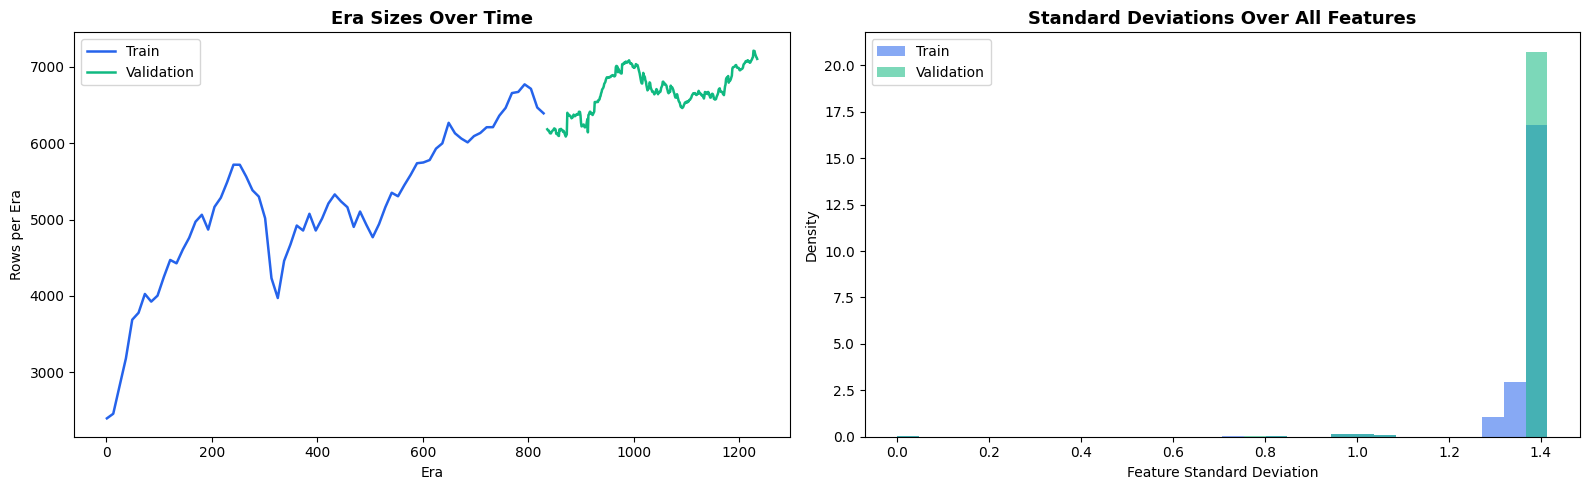

Top 10 Features according to absolute correlation with target:


feature_strength_33        0.012504
feature_strength_32        0.012464
feature_constitution_30    0.012276
feature_strength_31        0.011684
feature_charisma_151       0.011186
feature_constitution_29    0.010746
feature_constitution_33    0.010375
feature_constitution_32    0.010305
feature_charisma_149       0.010285
feature_charisma_40        0.010217
dtype: float64

ADF Stationarity Check on Top 10 Features (Per-Era Means):


,feature,adf_stat,adf_pvalue,stationary_at_5pct
0,feature_strength_33,-3.7414,0.0036,True
1,feature_strength_32,-3.7414,0.0036,True
2,feature_constitution_30,-3.7414,0.0036,True
3,feature_strength_31,-3.7414,0.0036,True
4,feature_charisma_151,-2.7646,0.0635,False
5,feature_constitution_29,-3.7414,0.0036,True
6,feature_constitution_33,-3.7414,0.0036,True
7,feature_constitution_32,-3.7414,0.0036,True
8,feature_charisma_149,-3.7414,0.0036,True
9,feature_charisma_40,-3.7414,0.0036,True


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

train_era_sizes = train_df.groupby(ERA_COL)[TARGET_COL].size()
val_era_sizes = validation_df.groupby(ERA_COL)[TARGET_COL].size()
axes[0].plot(train_era_sizes.index, train_era_sizes.to_numpy(), color='#2563eb', linewidth=1.8, label='Train')
axes[0].plot(val_era_sizes.index, val_era_sizes.to_numpy(), color='#10b981', linewidth=1.8, label='Validation')
axes[0].set_title('Era Sizes Over Time', weight='bold', fontsize=13)
axes[0].set_xlabel('Era')
axes[0].set_ylabel('Rows per Era')
axes[0].legend()

train_feat_stds = train_df[feature_columns].astype(np.float32).std()
val_feat_stds = validation_df[feature_columns].astype(np.float32).std()
axes[1].hist(train_feat_stds, bins=30, alpha=0.55, density=True, color='#2563eb', label='Train')
axes[1].hist(val_feat_stds, bins=30, alpha=0.55, density=True, color='#10b981', label='Validation')
axes[1].set_title('Standard Deviations Over All Features', weight='bold', fontsize=13)
axes[1].set_xlabel('Feature Standard Deviation')
axes[1].set_ylabel('Density')
axes[1].legend()

plt.tight_layout()
plt.show()

corr_with_target = train_df[feature_columns].corrwith(train_df[TARGET_COL]).abs().sort_values(ascending=False)
print('Top 10 Features according to absolute correlation with target:')
display(corr_with_target.head(10))

eda_stationarity_df = compute_eda_era_stationarity(train_df, list(corr_with_target.head(10).index), era_col=ERA_COL)
print('ADF Stationarity Check on Top 10 Features (Per-Era Means):')
display(eda_stationarity_df)

In [6]:
input_columns = [ERA_COL] + ([TICKER_COL] if TICKER_COL in train_df.columns and TICKER_COL in validation_df.columns else []) + feature_columns
X_train = train_df[input_columns].reset_index(drop=True)
y_train = train_df[TARGET_COL].astype(np.float32).reset_index(drop=True)
train_eras = train_df[ERA_COL].astype(np.int32).reset_index(drop=True)

X_validation = validation_df[input_columns].reset_index(drop=True)
y_validation = validation_df[TARGET_COL].astype(np.float32).reset_index(drop=True)
validation_eras = validation_df[ERA_COL].astype(np.int32).reset_index(drop=True)

# Retain only lightweight validation metadata for diagnostics export, date-aware staking, and free raw DataFrames
val_diag_meta = validation_df[[c for c in ('id', 'numerai_ticker', 'date', ERA_COL) if c in validation_df.columns]].reset_index(drop=True).copy()
val_era_dates = (
    val_diag_meta.groupby(ERA_COL, sort=True)['date'].first()
    if ('date' in val_diag_meta.columns and ERA_COL in val_diag_meta.columns)
    else None
)
del train_df, validation_df
gc.collect()

# Era-level purged CV splitter supporting 'timeseries', 'purged_kfold' (AFML Ch. 7), and 'cpcv' (AFML Ch. 12)
cv_object = build_era_cv_splits(
    train_eras,
    cv_strategy=cv_strategy,
    n_splits=n_splits,
    cv_split=cv_split,
    target_horizon_eras=target_horizon_eras,
    embargo_eras=embargo_eras,
)
print(
    f'Built {len(cv_object)} strictly era-purged CV fold(s) using cv_strategy={cv_strategy!r} '
    f'(horizon={target_horizon_eras} eras, embargo={embargo_eras} eras)'
)


Built 69 strictly era-purged CV fold(s) using cv_strategy='timeseries' (horizon=12 eras, embargo=1 eras)


In [7]:
raw_feature_sets = feature_metadata.get('feature_sets', {})
meta_set_names = {'small', 'medium', 'all'}
active_feature_set_cols = set(feature_columns)
unity_feature_groups_dict = {
    group_name: tuple(col for col in group_cols if col in active_feature_set_cols)
    for group_name, group_cols in raw_feature_sets.items()
    if group_name not in meta_set_names and isinstance(group_cols, list)
}
unity_feature_groups_dict = {k: v for k, v in unity_feature_groups_dict.items() if len(v) >= 2}
unity_feature_groups = tuple(sorted(unity_feature_groups_dict.items())) if unity_feature_groups_dict else None

numerai_extractions = NumeraiExtractions(
    era_col=ERA_COL,
    target_col=TARGET_COL,
    ticker_col=TICKER_COL,
    year_horizon_filter=None,
    variance_threshold=None,
    correlation_method='pandas_mean',
    abs_corr=True,
    top_k=None,
    feature_selection_percentile=None,
    sparse_selector=None,
    sparse_alpha=0.01,
    pca_n_components=None,
    quantize_scope='era',
    quantize_strategy='zscore',
    sequence_top_n=4,
    feature_groups=unity_feature_groups,
    basic_group_stats=None,
    fourier_period_eras=52,
    fourier_order=None,
    rolling_era_windows=(4, 12),
    include_rolling_era=False,
    era_lag_scales=(1, 2, 4),
    include_lag_diff=False,
    ticker_features=None,
    ticker_windows=(4, 12),
    ticker_lag_steps=None,
    era_dispersion_features=None,
    missing_fill_value=2.0,
)

bin_snapping_estimator = BinSnappingEstimator(
    extractor=clone(numerai_extractions),
    top_k=20,
    n_bins=5,
    correlation_method='pandas_mean',
    abs_corr=True,
    smoothing=0.0,
    agg_mode='mean',
    era_weighting=era_weighting,
    recency_decay=recency_decay,
    prediction_transform=None,
    bias_correction=None,
    walk_forward_step_eras=None,
    walk_forward_window=walk_forward_window,
    target_horizon_eras=target_horizon_eras,
    era_stride=1,
    era_col=ERA_COL,
    target_col=TARGET_COL,
    verbose=verbose,
    random_state=random_state,
)

lag_reversal_estimator = LagReversalEstimator(
    extractor=clone(numerai_extractions),
    lag=1,
    acf_mode='feature_mean',
    acf_metric='acf',
    acf_detrend='linear',
    acf_threshold=0.0,
    sign_mode='hard',
    top_k=None,
    correlation_method='pandas_mean',
    abs_corr=True,
    center_features=True,
    era_weighting=era_weighting,
    recency_decay=recency_decay,
    prediction_transform=None,
    bias_correction=None,
    walk_forward_step_eras=None,
    walk_forward_window=walk_forward_window,
    target_horizon_eras=target_horizon_eras,
    era_stride=1,
    era_col=ERA_COL,
    target_col=TARGET_COL,
    verbose=verbose,
    random_state=random_state,
)

persistence_estimator = PersistenceEstimator(
    extractor=None,
    ticker_col=TICKER_COL,
    persistence_mode='last',
    persistence_lag=target_horizon_eras,
    smoothing=0.0,
    top_k=None,
    correlation_method=None,
    abs_corr=True,
    era_weighting=era_weighting,
    recency_decay=recency_decay,
    prediction_transform=None,
    bias_correction=None,
    walk_forward_step_eras=None,
    walk_forward_window=walk_forward_window,
    target_horizon_eras=target_horizon_eras,
    era_stride=1,
    era_col=ERA_COL,
    target_col=TARGET_COL,
    verbose=verbose,
    random_state=random_state,
)

bin_snapping_pipeline = Pipeline([('estimator', bin_snapping_estimator)])
lag_reversal_pipeline = Pipeline([('estimator', lag_reversal_estimator)])
persistence_pipeline = Pipeline([('estimator', persistence_estimator)])
print('Baseline A pipeline ready:', bin_snapping_pipeline)
print('Baseline E pipeline ready:', lag_reversal_pipeline)
print('Persistence pipeline ready:', persistence_pipeline)

Baseline A pipeline ready: Pipeline(steps=[('estimator',
                 BinSnappingEstimator(extractor=NumeraiExtractions(feature_groups=(('signals',
                                                                                    ('feature_adv_20d_factor',
                                                                                     'feature_beta_factor',
                                                                                     'feature_book_to_price_factor',
                                                                                     'feature_dividend_yield_factor',
                                                                                     'feature_earnings_yield_factor',
                                                                                     'feature_growth_factor',
                                                                                     'feature_impact_cost_factor',
                                                   

# Params

## Grid

In [8]:
# SHARED `NumeraiExtractions` GRID SPACE (Used by both `BinSnappingEstimator` and `LagReversalEstimator`)
GRID_EXTRACTOR_PARAM_SPACE = {
    # ----------------------------------------------------------
    # EXTRACTOR — Era/Target Routing, Stride, Correlation & Feature Selection
    # ----------------------------------------------------------
    'estimator__extractor__era_col': [ERA_COL],
    'estimator__extractor__ticker_col': [TICKER_COL],
    'estimator__extractor__target_col': [
        TARGET_COL,
        # 'target_cyrusd_20',
        # 'target_teager2b_20',
    ],
    'estimator__extractor__year_horizon_filter': [
        None,
        # (1, 2, 3),
        # (4, 5, 6),
        # (7, 8, 9),
    ],
    'estimator__extractor__variance_threshold': [
        None,
        # 0.02,
        # 0.05,
        # 0.10,
    ],
    'estimator__extractor__correlation_method': [
        'pandas_mean',
        # None,
        # 'numerai_mean',
        # 'pearson',
        # 'spearman'
    ],
    'estimator__extractor__abs_corr': [
        True,
        # False,
    ],
    'estimator__extractor__top_k': [
        None,
        # 10,
        # 20,
        # 40,
    ],
    'estimator__extractor__feature_selection_percentile': [
        None,
        # 25.0,
        # 50.0,
        # 75.0,
        # 100.0,
    ],
    'estimator__extractor__sparse_selector': [
        None,
        # 'lasso',
        # 'elasticnet',
    ],
    'estimator__extractor__sparse_alpha': [
        0.01,
        # 0.001,
        # 0.1,
    ],
    'estimator__extractor__pca_n_components': [
        None,
        # 10,
        # 20,
        # 0.90,
    ],
    'estimator__extractor__quantize_scope': [
        'era',
        # 'train_fit',
        # 'global',
    ],
    'estimator__extractor__quantize_strategy': [
        'zscore',
        # 'quantile',
    ],
    'estimator__extractor__sequence_top_n': [
        4,
        # 2,
        # 8,
    ],
    'estimator__extractor__missing_fill_value': [
        2.0,
        # 0.0,
        # 4.0,
        # 'mean',
        # 'median',
        # 'era_mean',
        # 'era_median',
    ],

    # ----------------------------------------------------------
    # EXTRACTOR — Basic Group Stats, Fourier Harmonics & Era/Ticker Sequence Features
    # ----------------------------------------------------------
    'estimator__extractor__basic_group_stats': [
        None,
        # 'mean',
        # 'std',
        # 'skew',
        # 'mean|std',
        # 'mean|skew',
        # 'std|skew',
        # 'mean|std|skew',
    ],
    'estimator__extractor__fourier_period_eras': [
        52,
        # 26,
        # 13,
    ],
    'estimator__extractor__fourier_order': [
        None,
        # 1,
        # 2,
        # 3,
    ],
    'estimator__extractor__rolling_era_windows': [
        (4, 12),
        # (2, 6, 12),
        # (4, 8, 16),
    ],
    'estimator__extractor__include_rolling_era': [
        False,
        # True,
    ],
    'estimator__extractor__era_lag_scales': [
        (1, 2, 4),
        # (1, 2, 4, 8),
        # (2, 4, 8),
    ],
    'estimator__extractor__include_lag_diff': [
        False,
        # True,
    ],
    'estimator__extractor__ticker_features': [
        None,
        # 'rolling_mean',
        # 'momentum_diff',
        # 'weeks_since_high',
        # 'rolling_rank',
        # 'weeks_since_change',
        # 'expanding_stats',
        # 'raw_lags',
        # 'rolling_mean|momentum_diff',
        # 'rolling_mean|momentum_diff|rolling_rank',
        # 'expanding_stats|raw_lags',
        # 'rolling_mean|momentum_diff|weeks_since_high|rolling_rank|weeks_since_change|expanding_stats|raw_lags',
    ],
    'estimator__extractor__ticker_windows': [
        (4, 12),
        # (2, 6, 12),
    ],
    'estimator__extractor__ticker_lag_steps': [
        None,
        # (1, 2),
        # (1, 2, 4),
    ],
    'estimator__extractor__era_dispersion_features': [
        None,
        # 'mean',
        # 'std',
        # 'extreme_frac',
        # 'mean|std',
        # 'mean|extreme_frac',
        # 'std|extreme_frac',
        # 'mean|std|extreme_frac',
    ],
}

GRID_PARAM_SPACE_BIN_SNAPPING = {
    **GRID_EXTRACTOR_PARAM_SPACE,

    # ----------------------------------------------------------
    # MODEL — Baseline A (`BinSnappingEstimator` — Map Matching Lookup Table)
    # ----------------------------------------------------------
    'estimator__era_col': [ERA_COL],
    'estimator__target_col': [TARGET_COL],
    'estimator__correlation_method': [
        'pandas_mean',
        # None,
        # 'numerai_mean',
        # 'pearson',
        # 'spearman',
    ],
    'estimator__top_k': [
        20,
        # None,
        # 10,
        # 40,
    ],
    'estimator__n_bins': [
        5,
        # 3,
        # 7,
    ],
    'estimator__abs_corr': [
        True,
        # False,
    ],
    'estimator__smoothing': [
        0.0,
        # 25.0,
        # 50.0,
        # 100.0,
    ],
    'estimator__agg_mode': [
        'mean',
        # 'corr_weighted',
    ],
    'estimator__prediction_transform': [
        None,
        # 'era_zscore',
        # 'era_rank',
    ],
    'estimator__bias_correction': [
        None,
        # 'mean_residual',
    ],
    'estimator__walk_forward_step_eras': [
        None,
        # 10,
        # 20,
        # 40,
    ],
    'estimator__walk_forward_window': [
        walk_forward_window,
        # 'expanding',
        # 'sliding',
    ],
    'estimator__target_horizon_eras': [target_horizon_eras],
    'estimator__era_stride': [
        1,
        # 2,
        # 4,
        # 12,
    ],
    'estimator__era_weighting': [
        era_weighting,
        # None,
        # 'equal_era',
        # 'recency_linear',
        # 'recency_exp',
        # 'uniqueness',
    ],
    'estimator__recency_decay': [
        recency_decay,
        # 0.001,
        # 0.010,
    ],
    'estimator__verbose': [verbose],
    'estimator__random_state': [random_state],
}

GRID_PARAM_SPACE_LAG_REVERSAL = {
    **GRID_EXTRACTOR_PARAM_SPACE,

    # ----------------------------------------------------------
    # MODEL — Baseline E (`LagReversalEstimator` — Era Autocorrelation / PACF Sign & Shrinkage Rule)
    # ----------------------------------------------------------
    'estimator__era_col': [ERA_COL],
    'estimator__target_col': [TARGET_COL],
    'estimator__correlation_method': [
        'pandas_mean',
        # None,
        # 'numerai_mean',
        # 'pearson',
        # 'spearman',
    ],
    'estimator__lag': [
        1,
        # 2,
        # 4,
        # 6,
    ],
    'estimator__acf_mode': [
        'feature_mean',
        # 'feature_corr',
    ],
    'estimator__acf_metric': [
        'acf',
        # 'pacf',
    ],
    'estimator__acf_detrend': [
        'linear',
        # None,
        # 'constant',
    ],
    'estimator__acf_threshold': [
        0.0,
        # -0.05,
        # 0.05,
    ],
    'estimator__sign_mode': [
        'hard',
        # 'soft_threshold',
        # 'tanh',
    ],
    'estimator__top_k': [
        None,
        # 10,
        # 20,
        # 40,
    ],
    'estimator__abs_corr': [
        True,
        # False,
    ],
    'estimator__center_features': [
        True,
        # False,
    ],
    'estimator__prediction_transform': [
        None,
        # 'era_zscore',
        # 'era_rank',
    ],
    'estimator__bias_correction': [
        None,
        # 'mean_residual',
    ],
    'estimator__walk_forward_step_eras': [
        None,
        # 10,
        # 20,
        # 40,
    ],
    'estimator__walk_forward_window': [
        walk_forward_window,
        # 'expanding',
        # 'sliding',
    ],
    'estimator__target_horizon_eras': [target_horizon_eras],
    'estimator__era_stride': [
        1,
        # 2,
        # 4,
        # 12,
    ],
    'estimator__era_weighting': [
        era_weighting,
        # None,
        # 'equal_era',
        # 'recency_linear',
        # 'recency_exp',
        # 'uniqueness',
    ],
    'estimator__recency_decay': [
        recency_decay,
        # 0.001,
        # 0.010,
    ],
    'estimator__verbose': [verbose],
    'estimator__random_state': [random_state],
}

# Decoupled Persistence Grid Space (Does NOT inherit `GRID_EXTRACTOR_PARAM_SPACE`)
GRID_PARAM_SPACE_PERSISTENCE = {
    # ----------------------------------------------------------
    # MODEL — Baseline P (`PersistenceEstimator` — Brownlee Target Persistence / Zero-Rule)
    # ----------------------------------------------------------
    'estimator__era_col': [ERA_COL],
    'estimator__target_col': [TARGET_COL],
    'estimator__ticker_col': [TICKER_COL],
    'estimator__persistence_mode': [
        'last',
        # 'expanding_mean',
        # None,
    ],
    'estimator__persistence_lag': [target_horizon_eras],
    'estimator__smoothing': [
        0.0,
        # 10.0,
        # 25.0,
        # 50.0,
    ],
    'estimator__prediction_transform': [
        None,
        # 'era_zscore',
        # 'era_rank',
    ],
    'estimator__bias_correction': [
        None,
        # 'mean_residual',
    ],
    'estimator__walk_forward_step_eras': [
        None,
        # 10,
        # 20,
        # 40,
    ],
    'estimator__walk_forward_window': [
        walk_forward_window,
        # 'expanding',
        # 'sliding',
    ],
    'estimator__target_horizon_eras': [target_horizon_eras],
    'estimator__era_stride': [
        1,
        # 2,
        # 4,
        # 12,
    ],
    'estimator__era_weighting': [
        era_weighting,
        # None,
        # 'equal_era',
        # 'recency_linear',
        # 'recency_exp',
        # 'uniqueness',
    ],
    'estimator__recency_decay': [
        recency_decay,
        # 0.001,
        # 0.010,
    ],
    'estimator__verbose': [verbose],
    'estimator__random_state': [random_state],
}

## Bayesian

In [9]:
# BAYESIAN SEARCH ONLY
# Shared `BAYESIAN_EXTRACTOR_PARAM_SPACE` is used by both `BinSnappingEstimator` and `LagReversalEstimator`.
# Mode/selection parameters start with `None` (off); boolean `include_*` flags use `[False, True]`.
BAYESIAN_EXTRACTOR_PARAM_SPACE = dict()
BAYESIAN_PARAM_SPACE_BIN_SNAPPING = dict()
BAYESIAN_PARAM_SPACE_LAG_REVERSAL = dict()
BAYESIAN_PARAM_SPACE_PERSISTENCE = dict()
if SKOPT_AVAILABLE:
    BAYESIAN_EXTRACTOR_PARAM_SPACE = {
        # ----------------------------------------------------------
        # EXTRACTOR — Era/Target Routing, Stride, Correlation & Feature Selection
        # ----------------------------------------------------------
        'estimator__extractor__era_col': Categorical([ERA_COL]),
        'estimator__extractor__ticker_col': Categorical([TICKER_COL]),
        'estimator__extractor__target_col': Categorical([
            TARGET_COL,
        ]),
        'estimator__extractor__year_horizon_filter': Categorical([
            None,
            (1, 2, 3),
            (4, 5, 6),
            (7, 8, 9),
        ]),
        'estimator__extractor__variance_threshold': Categorical([
            None,
            0.02,
            0.05,
            0.10,
        ]),
        'estimator__extractor__correlation_method': Categorical([
            None,
            'pandas_mean',
            'numerai_mean',
            'pearson',
            'spearman',
        ]),
        'estimator__extractor__abs_corr': Categorical([True, False]),
        'estimator__extractor__top_k': Categorical([
            None,
            10,
            20,
            40,
        ]),
        'estimator__extractor__feature_selection_percentile': Categorical([
            None,
            25.0,
            50.0,
            75.0,
            100.0,
        ]),
        'estimator__extractor__sparse_selector': Categorical([
            None,
            'lasso',
            'elasticnet',
        ]),
        'estimator__extractor__sparse_alpha': Real(1e-4, 1e-1, prior='log-uniform'),
        'estimator__extractor__pca_n_components': Categorical([
            None,
            10,
            20,
            40,
        ]),
        'estimator__extractor__quantize_scope': Categorical([
            'era',
            'train_fit',
            'global',
        ]),
        'estimator__extractor__quantize_strategy': Categorical([
            'zscore',
            'quantile',
        ]),
        'estimator__extractor__sequence_top_n': Categorical([
            2,
            4,
            8,
        ]),
        'estimator__extractor__missing_fill_value': Categorical([
            2.0,
            0.0,
            4.0,
            'mean',
            'median',
            'era_mean',
            'era_median',
        ]),

        # ----------------------------------------------------------
        # EXTRACTOR — Basic Group Stats, Fourier Harmonics & Era/Ticker Sequence Features
        # ----------------------------------------------------------
        'estimator__extractor__basic_group_stats': Categorical([
            None,
            'mean',
            'std',
            'skew',
            'mean|std',
            'mean|skew',
            'std|skew',
            'mean|std|skew',
        ]),
        'estimator__extractor__fourier_period_eras': Categorical([
            52,
            26,
            13,
        ]),
        'estimator__extractor__fourier_order': Categorical([
            None,
            1,
            2,
            3,
        ]),
        'estimator__extractor__rolling_era_windows': Categorical([
            (4, 12),
            (2, 6, 12),
            (4, 8, 16),
        ]),
        'estimator__extractor__include_rolling_era': Categorical([False, True]),
        'estimator__extractor__era_lag_scales': Categorical([
            (1, 2, 4),
            (1, 2, 4, 8),
            (2, 4, 8),
        ]),
        'estimator__extractor__include_lag_diff': Categorical([False, True]),
        'estimator__extractor__ticker_features': Categorical([
            None,
            'rolling_mean',
            'momentum_diff',
            'weeks_since_high',
            'rolling_rank',
            'weeks_since_change',
            'expanding_stats',
            'raw_lags',
            'rolling_mean|momentum_diff',
            'rolling_mean|momentum_diff|rolling_rank',
            'expanding_stats|raw_lags',
            'rolling_mean|momentum_diff|weeks_since_high|rolling_rank|weeks_since_change|expanding_stats|raw_lags',
        ]),
        'estimator__extractor__ticker_windows': Categorical([
            (4, 12),
            (2, 6, 12),
        ]),
        'estimator__extractor__ticker_lag_steps': Categorical([
            None,
            (1, 2),
            (1, 2, 4),
        ]),
        'estimator__extractor__era_dispersion_features': Categorical([
            None,
            'mean',
            'std',
            'extreme_frac',
            'mean|std',
            'mean|extreme_frac',
            'std|extreme_frac',
            'mean|std|extreme_frac',
        ]),
    }

    BAYESIAN_PARAM_SPACE_BIN_SNAPPING = {
        **BAYESIAN_EXTRACTOR_PARAM_SPACE,

        # ----------------------------------------------------------
        # MODEL — Baseline A (`BinSnappingEstimator` — Map Matching Lookup Table)
        # ----------------------------------------------------------
        'estimator__era_col': Categorical([ERA_COL]),
        'estimator__target_col': Categorical([TARGET_COL]),
        'estimator__correlation_method': Categorical([
            None,
            'pandas_mean',
            'numerai_mean',
            'pearson',
            'spearman',
        ]),
        'estimator__top_k': Categorical([
            None,
            10,
            20,
            40,
        ]),
        'estimator__n_bins': Categorical([
            5,
            3,
            7,
        ]),
        'estimator__abs_corr': Categorical([True, False]),
        'estimator__smoothing': Real(0.0, 100.0),
        'estimator__agg_mode': Categorical(['mean', 'corr_weighted']),
        'estimator__prediction_transform': Categorical([
            None,
            'era_zscore',
            'era_rank',
        ]),
        'estimator__bias_correction': Categorical([
            None,
            'mean_residual',
        ]),
        'estimator__walk_forward_step_eras': Categorical([
            None,
            10,
            20,
            40,
        ]),
        'estimator__walk_forward_window': Categorical([
            'expanding',
            'sliding',
        ]),
        'estimator__target_horizon_eras': Categorical([target_horizon_eras]),
        'estimator__era_stride': Categorical([1]),
        'estimator__era_weighting': Categorical([
            None,
            'equal_era',
            'recency_linear',
            'recency_exp',
            'uniqueness',
            'uniqueness_decay',
        ]),
        'estimator__recency_decay': Real(0.001, 0.020),
        'estimator__verbose': Categorical([verbose]),
        'estimator__random_state': Categorical([random_state]),
    }
    BAYESIAN_PARAM_SPACE_BIN_SNAPPING = build_conditional_bayesian_spaces(
        drop_constant_dims(BAYESIAN_PARAM_SPACE_BIN_SNAPPING, bin_snapping_pipeline),
        total_n_iter=n_iter,
    )

    BAYESIAN_PARAM_SPACE_LAG_REVERSAL = {
        **BAYESIAN_EXTRACTOR_PARAM_SPACE,

        # ----------------------------------------------------------
        # MODEL — Baseline E (`LagReversalEstimator` — Era Autocorrelation / PACF Sign & Shrinkage Rule)
        # ----------------------------------------------------------
        'estimator__era_col': Categorical([ERA_COL]),
        'estimator__target_col': Categorical([TARGET_COL]),
        'estimator__correlation_method': Categorical([
            None,
            'pandas_mean',
            'numerai_mean',
            'pearson',
            'spearman',
        ]),
        'estimator__lag': Integer(1, 6),
        'estimator__acf_mode': Categorical(['feature_mean', 'feature_corr']),
        'estimator__acf_metric': Categorical(['acf', 'pacf']),
        'estimator__acf_detrend': Categorical([
            None,
            'linear',
            'constant',
        ]),
        'estimator__acf_threshold': Real(-0.20, 0.20),
        'estimator__sign_mode': Categorical([
            'hard',
            'soft_threshold',
            'tanh',
        ]),
        'estimator__top_k': Categorical([
            None,
            10,
            20,
            40,
        ]),
        'estimator__abs_corr': Categorical([True, False]),
        'estimator__center_features': Categorical([True, False]),
        'estimator__prediction_transform': Categorical([
            None,
            'era_zscore',
            'era_rank',
        ]),
        'estimator__bias_correction': Categorical([
            None,
            'mean_residual',
        ]),
        'estimator__walk_forward_step_eras': Categorical([
            None,
            10,
            20,
            40,
        ]),
        'estimator__walk_forward_window': Categorical([
            'expanding',
            'sliding',
        ]),
        'estimator__target_horizon_eras': Categorical([target_horizon_eras]),
        'estimator__era_stride': Categorical([1]),
        'estimator__era_weighting': Categorical([
            None,
            'equal_era',
            'recency_linear',
            'recency_exp',
            'uniqueness',
            'uniqueness_decay',
        ]),
        'estimator__recency_decay': Real(0.001, 0.020),
        'estimator__verbose': Categorical([verbose]),
        'estimator__random_state': Categorical([random_state]),
    }
    BAYESIAN_PARAM_SPACE_LAG_REVERSAL = build_conditional_bayesian_spaces(
        drop_constant_dims(BAYESIAN_PARAM_SPACE_LAG_REVERSAL, lag_reversal_pipeline),
        total_n_iter=n_iter,
    )

    # Decoupled Persistence Bayesian Space (Does NOT inherit `BAYESIAN_EXTRACTOR_PARAM_SPACE`)
    BAYESIAN_PARAM_SPACE_PERSISTENCE = {
        # ----------------------------------------------------------
        # MODEL — Baseline P (`PersistenceEstimator` — Brownlee Target Persistence / Zero-Rule)
        # ----------------------------------------------------------
        'estimator__era_col': Categorical([ERA_COL]),
        'estimator__target_col': Categorical([TARGET_COL]),
        'estimator__ticker_col': Categorical([TICKER_COL]),
        'estimator__persistence_mode': Categorical([
            None,
            'last',
            'expanding_mean',
        ]),
        'estimator__persistence_lag': Categorical([target_horizon_eras]),
        'estimator__smoothing': Real(0.0, 100.0),
        'estimator__prediction_transform': Categorical([
            None,
            'era_zscore',
            'era_rank',
        ]),
        'estimator__bias_correction': Categorical([
            None,
            'mean_residual',
        ]),
        'estimator__walk_forward_step_eras': Categorical([
            None,
            20,
            40,
        ]),
        'estimator__walk_forward_window': Categorical([
            'expanding',
            'sliding',
        ]),
        'estimator__target_horizon_eras': Categorical([target_horizon_eras]),
        'estimator__era_stride': Categorical([1]),
        'estimator__era_weighting': Categorical([
            None,
            'equal_era',
            'recency_linear',
            'recency_exp',
            'uniqueness',
            'uniqueness_decay',
        ]),
        'estimator__recency_decay': Real(0.001, 0.020),
        'estimator__verbose': Categorical([verbose]),
        'estimator__random_state': Categorical([random_state]),
    }
    BAYESIAN_PARAM_SPACE_PERSISTENCE = build_conditional_bayesian_spaces(
        drop_constant_dims(BAYESIAN_PARAM_SPACE_PERSISTENCE, persistence_pipeline),
        total_n_iter=n_iter,
    )

bin_snapping_param_names = set(bin_snapping_pipeline.get_params(deep=True))
lag_reversal_param_names = set(lag_reversal_pipeline.get_params(deep=True))
persistence_param_names = set(persistence_pipeline.get_params(deep=True))
assert set(GRID_PARAM_SPACE_BIN_SNAPPING).issubset(bin_snapping_param_names)
assert set(GRID_PARAM_SPACE_LAG_REVERSAL).issubset(lag_reversal_param_names)
assert set(GRID_PARAM_SPACE_PERSISTENCE).issubset(persistence_param_names)
for _bspace, _pnames in (
    (BAYESIAN_PARAM_SPACE_BIN_SNAPPING, bin_snapping_param_names),
    (BAYESIAN_PARAM_SPACE_LAG_REVERSAL, lag_reversal_param_names),
    (BAYESIAN_PARAM_SPACE_PERSISTENCE, persistence_param_names),
):
    _bkeys = set().union(*(sub.keys() for sub, _ in _bspace)) if isinstance(_bspace, list) else set(_bspace)
    assert _bkeys.issubset(_pnames)

if search_mode == 'bayes':
    bin_snapping_param_space = BAYESIAN_PARAM_SPACE_BIN_SNAPPING
    lag_reversal_param_space = BAYESIAN_PARAM_SPACE_LAG_REVERSAL
    persistence_param_space = BAYESIAN_PARAM_SPACE_PERSISTENCE
else:
    bin_snapping_param_space = GRID_PARAM_SPACE_BIN_SNAPPING
    lag_reversal_param_space = GRID_PARAM_SPACE_LAG_REVERSAL
    persistence_param_space = GRID_PARAM_SPACE_PERSISTENCE
print(f'Active search_mode={search_mode} | baseline_mode={baseline_mode}')

Active search_mode=bayes | baseline_mode=persistence


# Train

In [10]:
_train_t0 = time.perf_counter()
baseline_results = {}
search_summary_rows = []
cv_results_by_baseline = {}
fitted_default_models = {}

error_bin_cfg = {
    'mode': error_bin_mode,
    'pct_bins': error_pct_bins,
    'zero_tols': error_zero_tols,
    'abs_bins': error_abs_bins,
}

persistence_jobs = []
if baseline_mode in ('persistence', 'all'):
    persistence_jobs.append(('Baseline P (Persistence)', persistence_pipeline, persistence_param_space))

heavy_jobs = []
if baseline_mode in ('baseline_a', 'both', 'all'):
    heavy_jobs.append(('Baseline A (Bin-Snapping)', bin_snapping_pipeline, bin_snapping_param_space))
if baseline_mode in ('baseline_e', 'both', 'all'):
    heavy_jobs.append(('Baseline E (Lag-Reversal)', lag_reversal_pipeline, lag_reversal_param_space))

_cpu_count = os.cpu_count() or 1
_job_budget = _cpu_count if int(n_jobs) == -1 else max(1, int(n_jobs))
outer_jobs = min(_job_budget, len(heavy_jobs)) if heavy_jobs else 1

effective_cache_max_entries = (
    min(int(extraction_cache_max_entries), 2)
    if (outer_jobs > 1 and str(feature_set).strip().lower() in ('medium', 'all'))
    else int(extraction_cache_max_entries)
)
extraction_cache_cfg = {
    'enabled': extraction_cache_enabled,
    'max_entries': effective_cache_max_entries,
}

common_run_kwargs = dict(
    search_mode=search_mode,
    score_version=score_version,
    eval_mode=eval_mode,
    cv_object=cv_object,
    n_iter=n_iter,
    random_state=random_state,
    verbose=verbose,
    error_score=error_score,
    n_jobs=1,
    walk_forward_step_eras=walk_forward_step_eras,
    walk_forward_window=walk_forward_window,
    target_horizon_eras=target_horizon_eras,
    era_stride=era_stride,
    error_bin_config=error_bin_cfg,
    extraction_cache_config=extraction_cache_cfg,
)

# 1. Run Baseline P (Persistence) first in the main process on metadata-only columns (0 feature copies)
persistence_payloads = []
if persistence_jobs:
    persist_cols = [c for c in (ERA_COL, TICKER_COL) if c in X_train.columns]
    X_train_persist = X_train[persist_cols]
    X_val_persist = X_validation[persist_cols]
    print(f'Running Baseline P (Persistence) in main process on {persist_cols} (0 feature columns copied)')
    for b_name, b_pipe, b_space in persistence_jobs:
        persistence_payloads.append(
            run_baseline(
                b_name, b_pipe, b_space,
                X_train_persist, y_train, train_eras,
                X_val_persist, y_validation, validation_eras,
                [],
                **common_run_kwargs,
            )
        )
    del X_train_persist, X_val_persist

# 2. Run heavy feature baselines (A & E) in parallel via loky with memmap (max_nbytes='10M', at most 2 workers)
heavy_payloads = []
if heavy_jobs:
    print(
        f'Running {len(heavy_jobs)} heavy baseline(s) with outer_jobs={outer_jobs} '
        f'(n_jobs={n_jobs}, cpu_count={_cpu_count}, inner cv_n_jobs=1, extraction_cache_max_entries={effective_cache_max_entries})'
    )
    if outer_jobs > 1:
        heavy_payloads = Parallel(n_jobs=outer_jobs, backend='loky', max_nbytes='10M')(
            delayed(run_baseline)(
                b_name, b_pipe, b_space,
                X_train, y_train, train_eras,
                X_validation, y_validation, validation_eras,
                feature_columns,
                **common_run_kwargs,
            )
            for b_name, b_pipe, b_space in heavy_jobs
        )
    else:
        heavy_payloads = [
            run_baseline(
                b_name, b_pipe, b_space,
                X_train, y_train, train_eras,
                X_validation, y_validation, validation_eras,
                feature_columns,
                **common_run_kwargs,
            )
            for b_name, b_pipe, b_space in heavy_jobs
        ]

# Merge in original A -> E -> P order
payloads = list(heavy_payloads) + list(persistence_payloads)
for b_name, b_results, b_cv_df, b_summary_row, b_default_model in payloads:
    baseline_results.update(b_results)
    cv_results_by_baseline[b_name] = b_cv_df
    search_summary_rows.append(b_summary_row)
    fitted_default_models[b_name] = b_default_model

train_elapsed_s = time.perf_counter() - _train_t0
print(f'Completed {len(payloads)} baseline(s) in {train_elapsed_s:.1f}s (heavy outer_jobs={outer_jobs})')
baseline_interpretability = extract_baseline_interpretability(fitted_default_models)
del X_train, y_train, train_eras, X_validation, fitted_default_models
del payloads, heavy_payloads, persistence_payloads
clear_extraction_cache()
gc.collect()

Running Baseline P (Persistence) in main process on ['era', 'numerai_ticker'] (0 feature columns copied)
  [AFML Purge | Baseline P (Persistence)] Purged 1 trailing train era(s) (cutoff <= era 824, min_val_era=836, horizon=12) before static validation fits.
--- Baseline P (Persistence) — Final Training Scores ---
Percentage Summary | Numerai CORR: -0.87% | Positive Eras: 34.8% | Era Consistency (>0.002): 30.4% | Directional Accuracy: 29.8%
Numerai CORR: -0.0087
Spearman Correlation: -0.0112
Average Payout (Legacy Spearman Proxy): -0.0561
Sharpe Ratio (Numerai / Lo-Adj / Spearman): -0.4812 / -0.4674 / -0.6451 | PSR (SR > 0): 0.0000 | MinTRL: inf eras
Cumulative CORR Drawdown: 0.6423 pts | Max TuW: 68 eras (1.31 yr) | HHI (+ / -): 0.0249 / 0.0107
Mean Absolute Error (MAE): 0.2207
Forecast Bias (mean(y - y_hat)): -0.0005
Directional Hit Rate: 0.2982 (29.8%)
Era CORR White-Noise & Regime Tests | Lag-1 ACF: -0.0377 | Ljung-Box p: 0.9468 | ARCH-LM p: 1.0000 | ADF p: 0.0784
Era CORR Tail Risk

0

In [11]:
comparison_columns = [
    'variant',
    'score_version',
    'train_corr',
    'validation_corr',
    'validation_spearman',
    'validation_payout',
    'era_consistency_pct',
    'validation_sharpe',
    'validation_lo_sharpe',
    'validation_psr',
    'validation_dsr',
    'effective_n_trials_onc',
    'validation_fnc',
    'validation_fnc_sharpe',
    'tuw_max_eras',
    'hhi_pos',
    'hhi_neg',
    'validation_spearman_sharpe',
    'validation_mae',
    'forecast_bias',
    'directional_hit_rate',
    'era_corr_lag1_acf',
    'ljung_box_pvalue',
    'arch_lm_pvalue',
    'adf_pvalue',
    'era_corr_skew',
    'era_corr_kurtosis',
    'jarque_bera_pvalue',
    'feature_exposure',
    'corr_drawdown',
    'start_capital',
    'end_capital',
    'total_profit',
    'total_return_pct',
    'money_drawdown_pct',
    'max_drawdown_gbp',
    'worst_round_gbp',
    'corr_gap',
    'sanity_status',
]
comparison_df = (
    pd.DataFrame([{column: result.get(column, np.nan) for column in comparison_columns} for result in baseline_results.values()])
    .sort_values(['validation_sharpe', 'validation_corr'], ascending=False, kind='stable')
    .reset_index(drop=True)
)
search_summary_df = (
    pd.DataFrame(search_summary_rows)
    .sort_values('best_cv_score', ascending=False, kind='stable')
    .reset_index(drop=True)
)

# Select the locked winner strictly from Train CV (never pick on held-out validation!)
cv_winner_baseline = str(search_summary_df.loc[0, 'baseline'])
preferred_locked_variants = [
    f'{cv_winner_baseline} [Tuned]',
    f'{cv_winner_baseline} [Tuned Walk-Forward]',
    f'{cv_winner_baseline} [Default]',
]
best_variant_name = next(
    (v for v in preferred_locked_variants if v in baseline_results),
    str(comparison_df.loc[0, 'variant']),
)
best_validation_era_corrs = baseline_results[best_variant_name]['validation_era_corrs']
best_validation_corr = baseline_results[best_variant_name]['validation_corr']

print(f'Train-CV-Locked Winner (evaluated once on held-out validation): {best_variant_name}')
display_compact_dataframe(
    search_summary_df.drop(columns=['best_params'], errors='ignore'),
    title=f'Train CV Search Summary ({search_mode}, score_version={score_version}, refit=False):',
)
print('Full 4-layer Executive Scorecard, Money Visuals, Diagnostics & AFML Story follow in # Analysis.')
cv_analysis_artifacts = extract_cv_analysis_artifacts(
    cv_results_by_baseline,
    top_n=10,
    results_dir=results_dir,
    timestamp=timestamp,
    experiment_name=experiment_name,
    search_mode=search_mode,
    save_results=save_results,
)
del cv_results_by_baseline
gc.collect()

Train-CV-Locked Winner (evaluated once on held-out validation): Baseline P (Persistence) [Tuned]
Train CV Search Summary (bayes, score_version=v1_skepta, refit=False):


,baseline,search_mode,score_version,best_cv_score,best_cv_corr,best_cv_score_pct,pbo_cscv
0,Baseline P (Persistence),bayes,v1_skepta,0.003028,0.003,0.3,NaN


Full 4-layer Executive Scorecard, Money Visuals, Diagnostics & AFML Story follow in # Analysis.


0

# Analysis

## Executive Scorecard
Compact **Money Table** and **Science Table** (7–8 columns each, zero horizontal truncation) plus lightweight `summary_<model_tag>.json` export for cross-notebook comparison.

In [12]:
money_scorecard_df, science_scorecard_df = build_executive_scorecard_tables(
    comparison_df,
    best_variant_name=best_variant_name,
)
print(f'Train-CV-Locked Winner: {best_variant_name}')
display_compact_dataframe(
    money_scorecard_df,
    title='1A. Money Table (One-Wallet Staking P&L, Drawdowns & Time-Underwater):',
)
display_compact_dataframe(
    science_scorecard_df,
    title='1B. Science Table (CORR, Overfit Gap, Sharpe, PSR/DSR & Sanity):',
)

if save_results:
    results_dir.mkdir(parents=True, exist_ok=True)
    comparison_df.to_csv(results_dir / f'{timestamp}_{experiment_name}_comparison.csv', index=False)
    winner_summary_json_path = export_winner_scorecard_json(
        comparison_df,
        best_variant_name=best_variant_name,
        model_tag=model_tag,
        output_dir=results_dir,
        experiment_meta={
            'experiment_name': experiment_name,
            'timestamp': timestamp,
            'data_version': data_version,
            'target_col': TARGET_COL,
            'feature_set': feature_set,
            'era_stride': era_stride,
            'search_mode': search_mode,
            'score_version': score_version,
            'cv_strategy': cv_strategy,
            'eval_mode': eval_mode,
        },
    )
    print('Exported cross-notebook winner summary JSON:', winner_summary_json_path)

if export_diagnostics or save_results:
    results_dir.mkdir(parents=True, exist_ok=True)
    diagnostics_parquet_path = export_diagnostics_predictions(
        val_diag_meta,
        baseline_results[best_variant_name]['validation_preds'],
        results_dir / 'validation_predictions.parquet',
        era_col=ERA_COL,
    )
    print('Exported Numerai Diagnostics predictions Parquet (MMC & FNC):', diagnostics_parquet_path)

Train-CV-Locked Winner: Baseline P (Persistence) [Tuned]
1A. Money Table (One-Wallet Staking P&L, Drawdowns & Time-Underwater):


,variant,end_capital,total_return_pct,money_drawdown_pct,max_drawdown_gbp,worst_round_gbp,tuw_max_eras
0,[WINNER] Baseline P (Persistence) [Tuned],1117.76,11.78,-1.57,-17.70,-1.94,2.71 yr (141e)
1,Baseline P (Persistence) [Tuned Walk-Forward],1116.38,11.64,-2.37,-27.15,-2.19,1.50 yr (78e)
2,Baseline P (Persistence) [Walk-Forward],1013.49,1.35,-3.33,-34.51,-2.17,5.33 yr (277e)
3,Baseline P (Persistence) [Default],990.74,-0.93,-9.64,-96.44,-3.34,4.23 yr (220e)


1B. Science Table (CORR, Overfit Gap, Sharpe, PSR/DSR & Sanity):


,variant,train_corr,validation_corr,corr_gap,validation_sharpe,validation_psr,validation_dsr,sanity_status
0,[WINNER] Baseline P (Persistence) [Tuned],0.0033,0.0060,-0.0027,0.4043,1.0000,1.0000,OK
1,Baseline P (Persistence) [Tuned Walk-Forward],0.0033,0.0060,-0.0027,0.3906,1.0000,1.0000,OK
2,Baseline P (Persistence) [Walk-Forward],-0.0087,0.0008,-0.0095,0.0389,0.7824,0.7824,LOW_SIGNAL_WARNING
3,Baseline P (Persistence) [Default],-0.0087,-0.0003,-0.0084,-0.0148,0.3835,0.3835,LOW_SIGNAL_WARNING


Exported cross-notebook winner summary JSON: /kaggle/working/results_numerai_v6.0_all_eras_stride12_baselines_ae_target_bayes/summary_baselines_ae.json
Exported Numerai Diagnostics predictions Parquet (MMC & FNC): /kaggle/working/results_numerai_v6.0_all_eras_stride12_baselines_ae_target_bayes/validation_predictions.parquet


## Core Performance & Money Visuals
Realistic Live vs. Conservative Floor staking equity curve, 500-path block-bootstrap Monte Carlo risk, Cumulative Validation CORR across all variants, and Rolling 20-Era Validation CORR regime stability.

### NumerAPI v6.0 Dataset Discovery & True MMC vs BMC Proxy Check
Lists every published `v6.0/` file via `NumerAPI`, checks whether true `meta_model.parquet` exists, and falls back cleanly to a v6 benchmark/example predictions file labeled **BMC proxy (benchmark, NOT true MMC)**.

In [13]:
v6_contrib_info = discover_and_fetch_v6_meta_or_benchmark(
    data_version=data_version,
    data_folder=data_folder,
    workspace_root=workspace_root,
    auto_download=True,
    verbose=True,
)

=== NumerAPI Dataset Discovery (v6.0) ===
All v6.0 files found (14):
  - v6.0/features.json
  - v6.0/live.parquet
  - v6.0/live_benchmark_models.parquet
  - v6.0/live_example_preds.csv
  - v6.0/live_example_preds.parquet
  - v6.0/live_neutralizer.parquet
  - v6.0/train.parquet
  - v6.0/train_benchmark_models.parquet
  - v6.0/train_neutralizer.parquet
  - v6.0/validation.parquet
  - v6.0/validation_benchmark_models.parquet
  - v6.0/validation_example_preds.csv
  - v6.0/validation_example_preds.parquet
  - v6.0/validation_neutralizer.parquet

Filtered (meta, benchmark, neutralizer, example) (10):
  - v6.0/live_benchmark_models.parquet
  - v6.0/live_example_preds.csv
  - v6.0/live_example_preds.parquet
  - v6.0/live_neutralizer.parquet
  - v6.0/train_benchmark_models.parquet
  - v6.0/train_neutralizer.parquet
  - v6.0/validation_benchmark_models.parquet
  - v6.0/validation_example_preds.csv
  - v6.0/validation_example_preds.parquet
  - v6.0/validation_neutralizer.parquet

[MMC Status] No 

### Simulated Numerai Staking P&L Dashboard (£)

Active Staking Basis: BMC proxy (benchmark, NOT true MMC)
  -> Reason: No v6.0 meta_model.parquet published yet, so true MMC / NMMC cannot be computed in backtest. Falling back to validation_benchmark_models.parquet (saved at /kaggle/input/notebooks/svendaj/numerai-data-v6-0-unity/v6.0/validation_benchmark_models.parquet) to compute BMC proxy (benchmark, NOT true MMC).


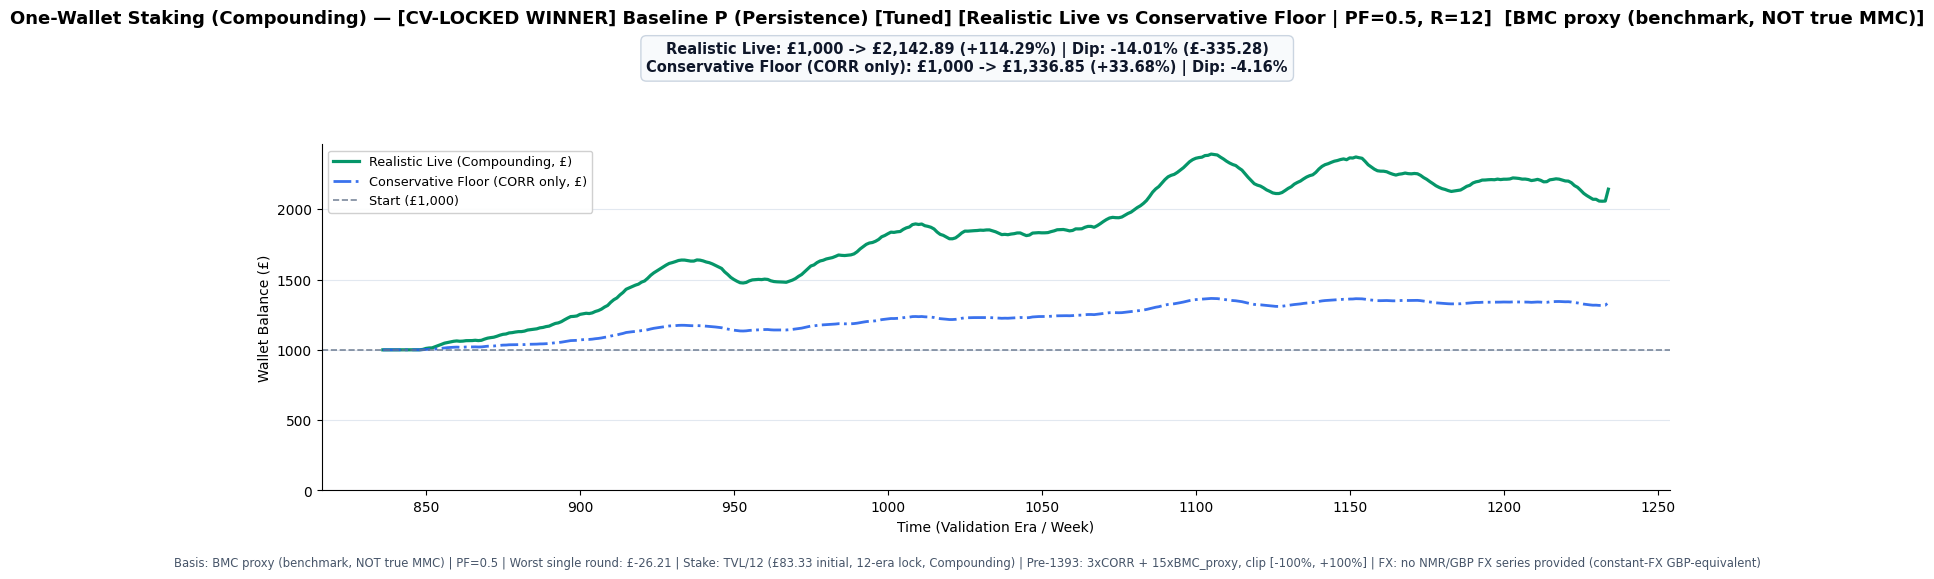

[CV-LOCKED WINNER] Baseline P (Persistence) [Tuned] | Realistic Live (PF=0.5, 0.5x BMC, R=12): £2,142.89 (+114.29%, Dip -14.01%) | Conservative Floor (CORR only, PF=0.5, R=12): £1,336.85 (+33.68%, Dip -4.16%) | Basis: BMC proxy (benchmark, NOT true MMC)


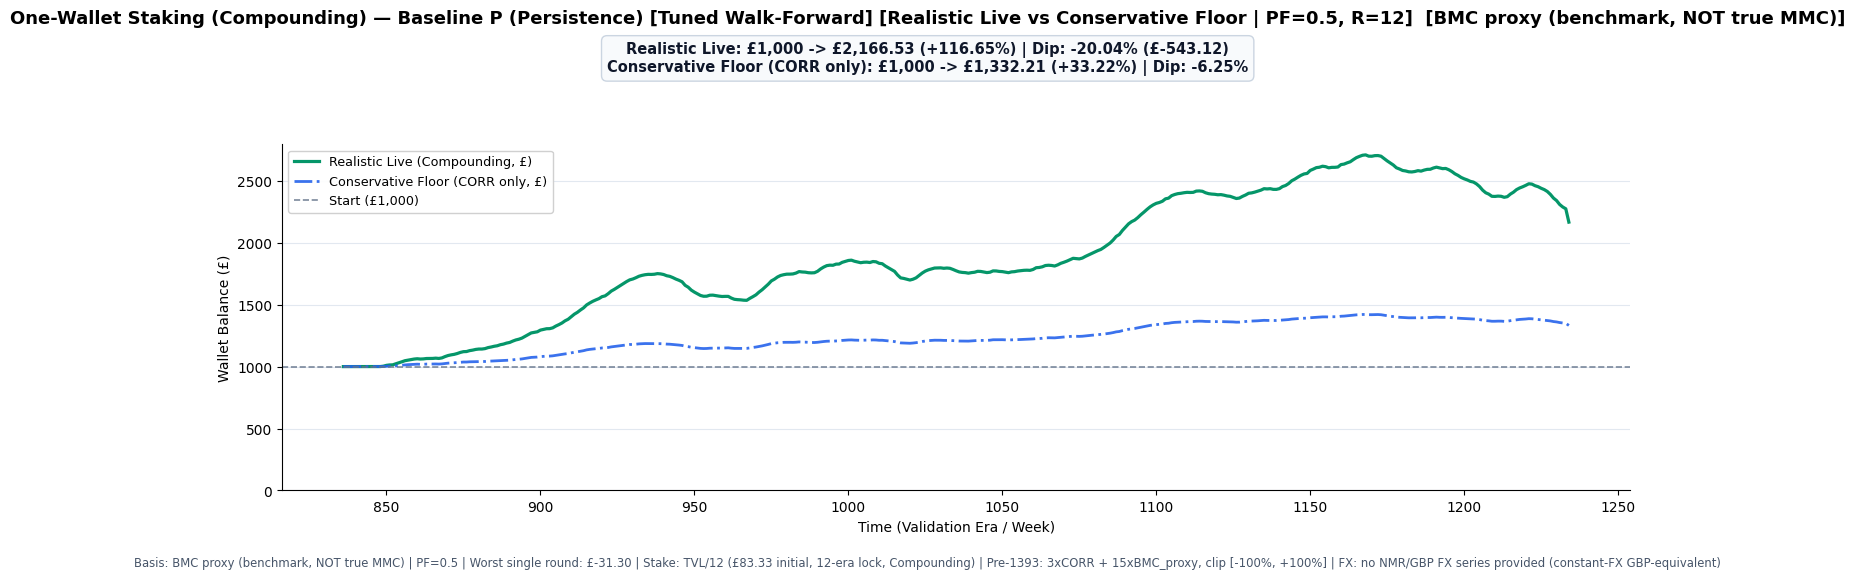

Baseline P (Persistence) [Tuned Walk-Forward] | Realistic Live (PF=0.5, 0.5x BMC, R=12): £2,166.53 (+116.65%, Dip -20.04%) | Conservative Floor (CORR only, PF=0.5, R=12): £1,332.21 (+33.22%, Dip -6.25%) | Basis: BMC proxy (benchmark, NOT true MMC)


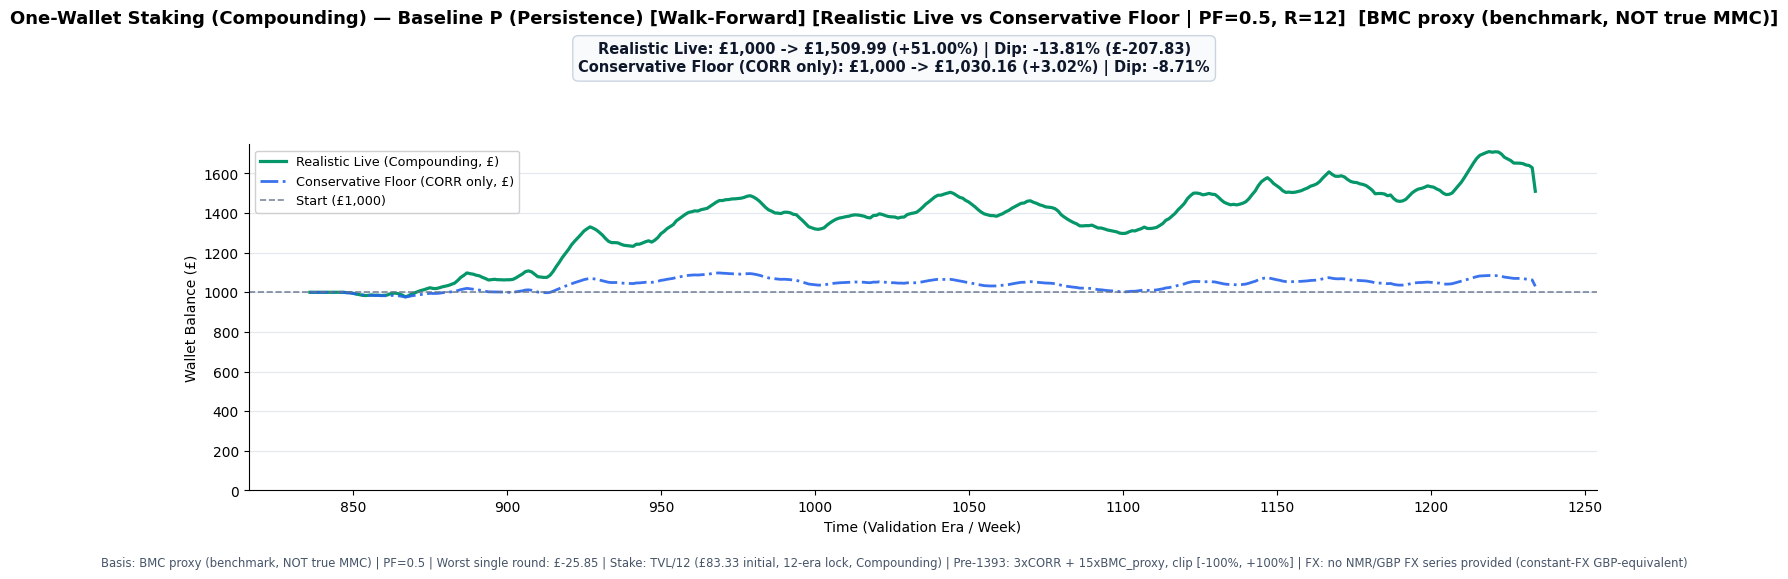

Baseline P (Persistence) [Walk-Forward] | Realistic Live (PF=0.5, 0.5x BMC, R=12): £1,509.99 (+51.00%, Dip -13.81%) | Conservative Floor (CORR only, PF=0.5, R=12): £1,030.16 (+3.02%, Dip -8.71%) | Basis: BMC proxy (benchmark, NOT true MMC)


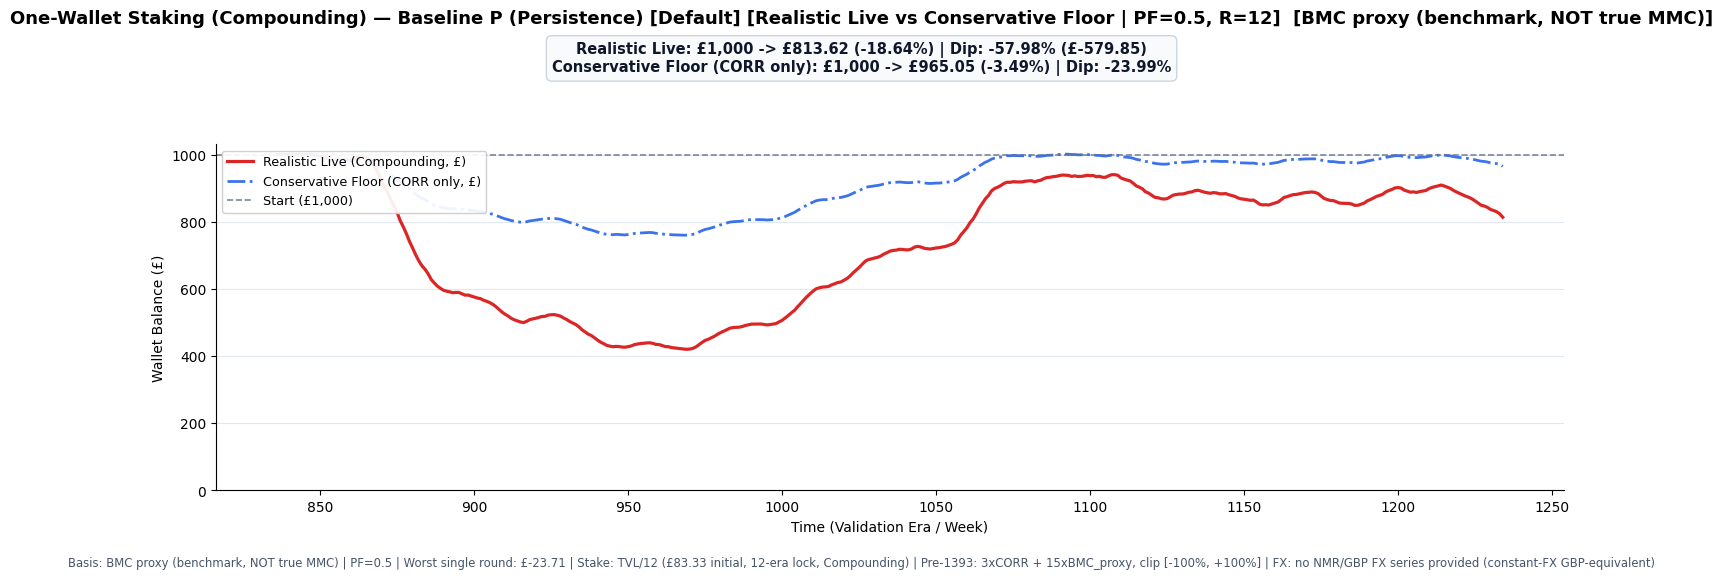

Baseline P (Persistence) [Default] | Realistic Live (PF=0.5, 0.5x BMC, R=12): £813.62 (-18.64%, Dip -57.98%) | Conservative Floor (CORR only, PF=0.5, R=12): £965.05 (-3.49%, Dip -23.99%) | Basis: BMC proxy (benchmark, NOT true MMC)
Dual-Scenario Realistic Live Staking Table (Conservative Floor vs. Realistic Live):


,variant,conservative_end_gbp,conservative_return_pct,conservative_worst_dip_pct,conservative_mc_p_profit_pct,realistic_live_end_gbp,realistic_live_return_pct,realistic_live_worst_dip_pct,realistic_live_mc_p_profit_pct,realistic_live_mc_median_gbp,payout_factor,bmc_haircut,concurrent_rounds
0,Baseline P (Persistence) [Tuned],1336.85,33.68,-4.16,100.0,2142.89,114.29,-14.01,99.8,2217.91,0.5,0.5,12
1,Baseline P (Persistence) [Tuned Walk-Forward],1332.21,33.22,-6.25,99.6,2166.53,116.65,-20.04,99.6,2292.39,0.5,0.5,12
2,Baseline P (Persistence) [Walk-Forward],1030.16,3.02,-8.71,61.0,1509.99,51.00,-13.81,92.8,1526.83,0.5,0.5,12
3,Baseline P (Persistence) [Default],965.05,-3.49,-23.99,46.0,813.62,-18.64,-57.98,40.2,881.92,0.5,0.5,12


3934

In [14]:
val_mmc_df = val_diag_meta.assign(**{TARGET_COL: y_validation.to_numpy(dtype=np.float32)})
staking_basis_label = v6_contrib_info['basis_label']
staking_is_proxy = bool(v6_contrib_info['mmc_is_proxy'])
print(f"Active Staking Basis: {staking_basis_label}")
print(f"  -> Reason: {v6_contrib_info['reason']}")

stake_pnl_by_variant = {}
variant_era_mmc_by_variant = {}
live_scenarios_by_variant = {}
staking_summary_rows = []
for variant_name in comparison_df['variant'].tolist():
    is_best_variant = (variant_name == best_variant_name)
    variant_slug = (
        variant_name.lower()
        .replace(' ', '_')
        .replace('(', '')
        .replace(')', '')
        .replace('[', '')
        .replace(']', '')
        .replace('-', '_')
    )
    variant_era_corrs = baseline_results[variant_name]['validation_era_corrs']
    variant_era_contrib = compute_per_era_mmc(
        val_mmc_df,
        baseline_results[variant_name]['validation_preds'],
        meta_model_path=v6_contrib_info['meta_model_path'],
        benchmark_path=v6_contrib_info['benchmark_path'],
        is_benchmark_proxy=staking_is_proxy,
        era_col=ERA_COL,
        target_col=TARGET_COL,
    )
    variant_era_mmc_by_variant[variant_name] = variant_era_contrib

    live_scenarios_by_variant[variant_name] = simulate_live_staking_scenarios(
        variant_era_corrs,
        per_era_mmc=variant_era_contrib,
        mmc_is_proxy=staking_is_proxy,
        total_capital=1000.0,
        settlement_rounds=12,
        weekly_concurrent_rounds=12,
        conservative_payout_factor=0.5,
        live_payout_factor=0.5,
        bmc_proxy_haircut=0.5,
        n_sims=500,
        block_size=12,
        random_state=random_state,
        title=variant_name,
        era_dates=val_era_dates,
    )

    title_label = f'[CV-LOCKED WINNER] {variant_name}' if is_best_variant else variant_name
    pnl_save_path = (
        results_dir / f'{timestamp}_{experiment_name}_{variant_slug}_stake_pnl_dashboard.png'
        if save_results
        else None
    )
    haircutted_contrib = (
        pd.Series(variant_era_contrib, dtype=np.float64) * (0.5 if staking_is_proxy else 1.0)
        if variant_era_contrib is not None
        else None
    )
    if haircutted_contrib is not None:
        haircutted_contrib.name = 'bmc_proxy' if staking_is_proxy else 'mmc'
    stake_pnl_by_variant[variant_name] = plot_stake_pnl_dashboard(
        variant_era_corrs,
        per_era_mmc=haircutted_contrib,
        mmc_is_proxy=staking_is_proxy,
        conservative_pnl=live_scenarios_by_variant[variant_name]['conservative_floor']['pnl'],
        title=f'{title_label} [Realistic Live vs Conservative Floor | PF=0.5, R=12]',
        total_capital=1000.0,
        concurrent_rounds=12,
        settlement_rounds=12,
        payout_factor=0.5,
        payout_rule='auto',
        staking_mode='compound',
        era_dates=val_era_dates,
        save_path=pnl_save_path,
    )

    v_pnl = stake_pnl_by_variant[variant_name]
    c_pnl = live_scenarios_by_variant[variant_name]['conservative_floor']['pnl']
    mean_contrib = float(variant_era_contrib.mean()) if variant_era_contrib is not None and len(variant_era_contrib) > 0 else np.nan
    contrib_col_name = 'validation_bmc_proxy' if staking_is_proxy else 'validation_true_mmc'
    staking_summary_rows.append({
        'variant': variant_name,
        'staking_basis': v_pnl['score_basis'],
        'staking_mode': 'One-Wallet (Compounding, PF=0.5, R=12)',
        'validation_corr': round(float(variant_era_corrs.mean()), 4),
        contrib_col_name: round(mean_contrib, 4) if np.isfinite(mean_contrib) else np.nan,
        'start_capital': round(float(v_pnl['start_capital']), 2),
        'end_capital': round(float(v_pnl['end_capital']), 2),
        'total_return_pct': round(float(v_pnl['total_return_pct']), 2),
        'worst_dip_pct': round(float(v_pnl['money_drawdown_pct']), 2),
        'worst_dip_gbp': round(float(v_pnl['max_drawdown_gbp']), 2),
        'worst_round_gbp': round(float(v_pnl['worst_round_gbp']), 2),
    })
    print(
        f"{title_label} | Realistic Live (PF=0.5, 0.5x BMC, R=12): £{v_pnl['end_capital']:,.2f} ({v_pnl['total_return_pct']:+.2f}%, Dip {v_pnl['money_drawdown_pct']:.2f}%) | "
        f"Conservative Floor (CORR only, PF=0.5, R=12): £{c_pnl['end_capital']:,.2f} ({c_pnl['total_return_pct']:+.2f}%, Dip {c_pnl['money_drawdown_pct']:.2f}%) | "
        f"Basis: {v_pnl['score_basis']}"
    )

staking_comparison_df = pd.DataFrame(staking_summary_rows)
live_staking_scenarios_df = build_live_staking_scenarios_df(live_scenarios_by_variant)
comparison_df['staking_basis'] = comparison_df['variant'].map(
    staking_comparison_df.set_index('variant')['staking_basis']
)
if staking_is_proxy:
    comparison_df['validation_bmc_proxy'] = comparison_df['variant'].map(
        staking_comparison_df.set_index('variant')['validation_bmc_proxy']
    )
elif v6_contrib_info['basis_kind'] == 'true_mmc':
    comparison_df['validation_true_mmc'] = comparison_df['variant'].map(
        staking_comparison_df.set_index('variant')['validation_true_mmc']
    )
display_compact_dataframe(
    live_staking_scenarios_df,
    title='Dual-Scenario Realistic Live Staking Table (Conservative Floor vs. Realistic Live):',
)
best_stake_pnl = stake_pnl_by_variant[best_variant_name]
del val_mmc_df, val_diag_meta
gc.collect()

### Monte Carlo Block-Bootstrap Risk Analysis (£)

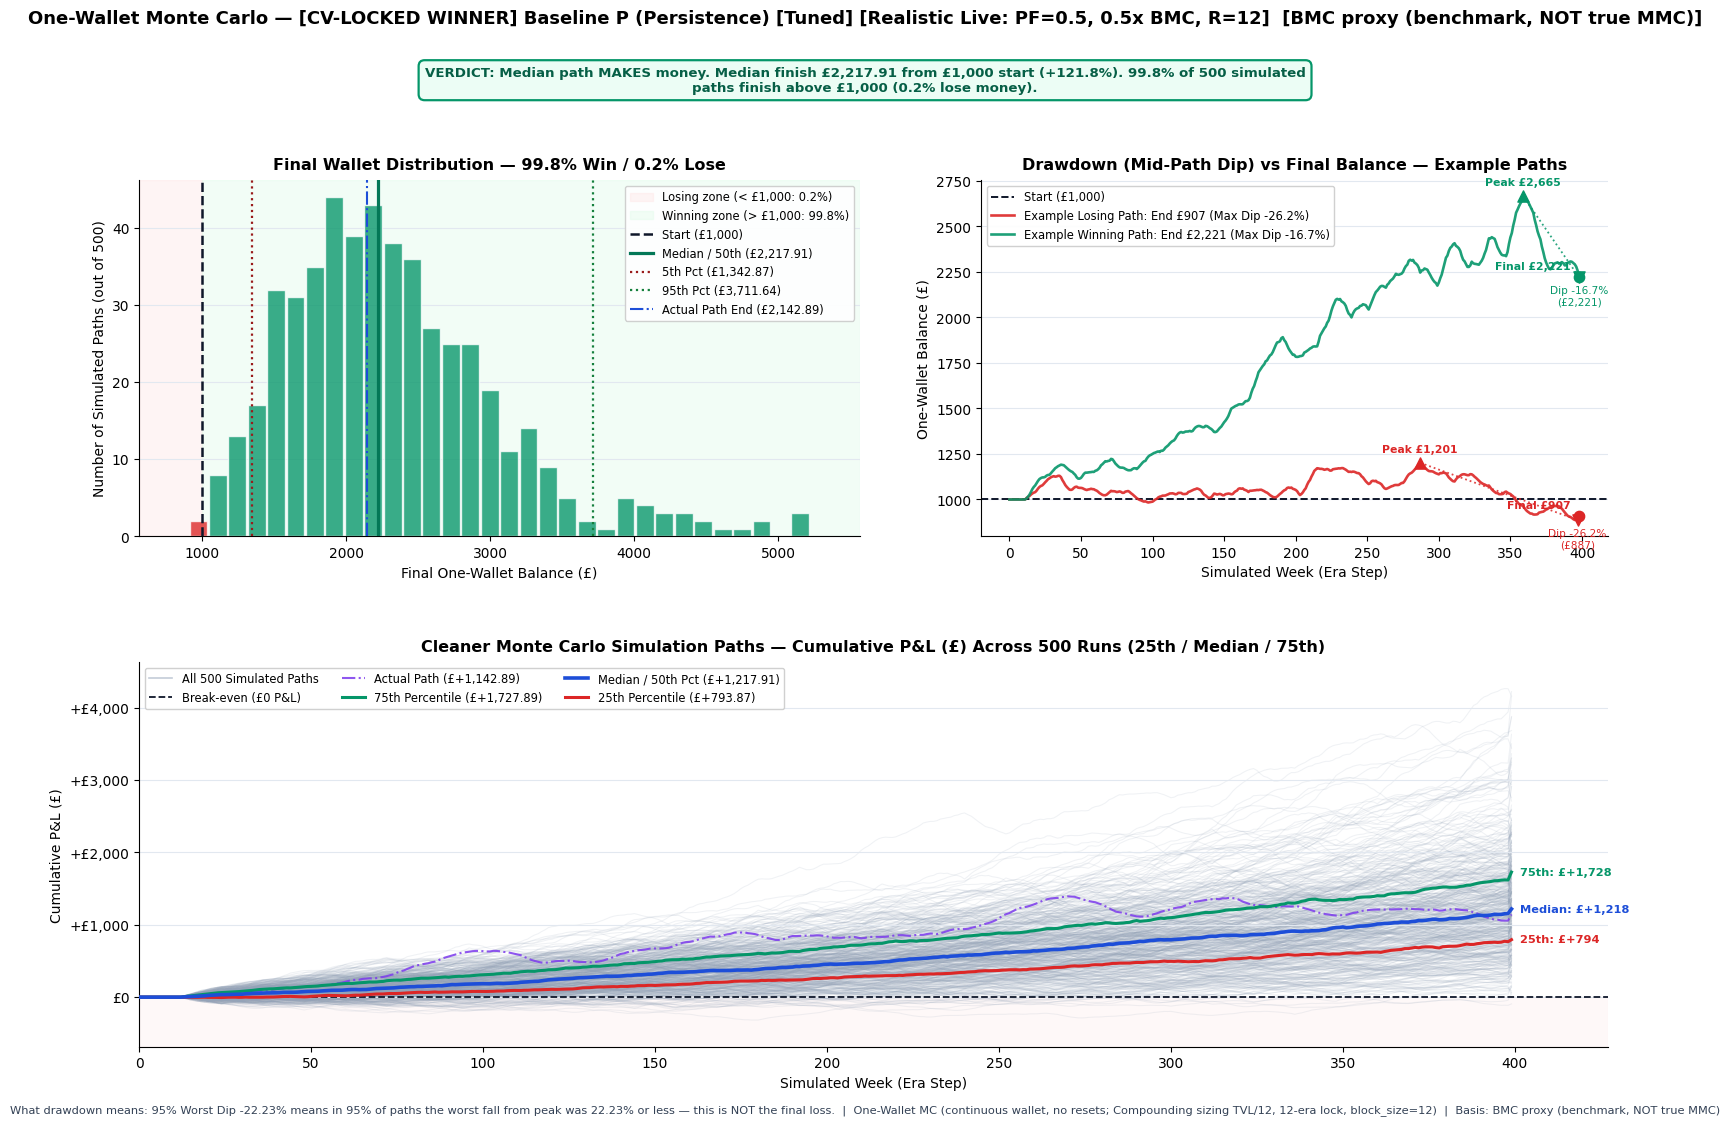

[CV-LOCKED WINNER] Baseline P (Persistence) [Tuned] — VERDICT: Median path MAKES money. Median finish £2,217.91 from £1,000 start (+121.8%). 99.8% of 500 simulated paths finish above £1,000 (0.2% lose money).

How to read Drawdown vs Final Balance (Plain English):
  • Drawdown is the biggest peak-to-trough dip DURING the journey — NOT your final profit or loss.
  • Worked example (Winning path with a drawdown): Start £1,000 -> rises to £1,200 peak -> dips to £1,100 (-8.3% drawdown from peak) -> recovers to £1,300. You still finish +£300 ABOVE £1,000 despite the dip.
  • Worked example (Losing path with a small drawdown): Start £1,000 -> drifts down to £955 (-4.5% dip) and ends at £984.81. A small drawdown still finishes BELOW £1,000 if it never recovers.
  • Median (50th) vs 95th percentile are DIFFERENT paths: Median = typical path; 95th = lucky top 5% of paths.
  • One-Wallet MC: Simulates ONE continuous wallet from start to finish over the full validation period with no resets.
  • 

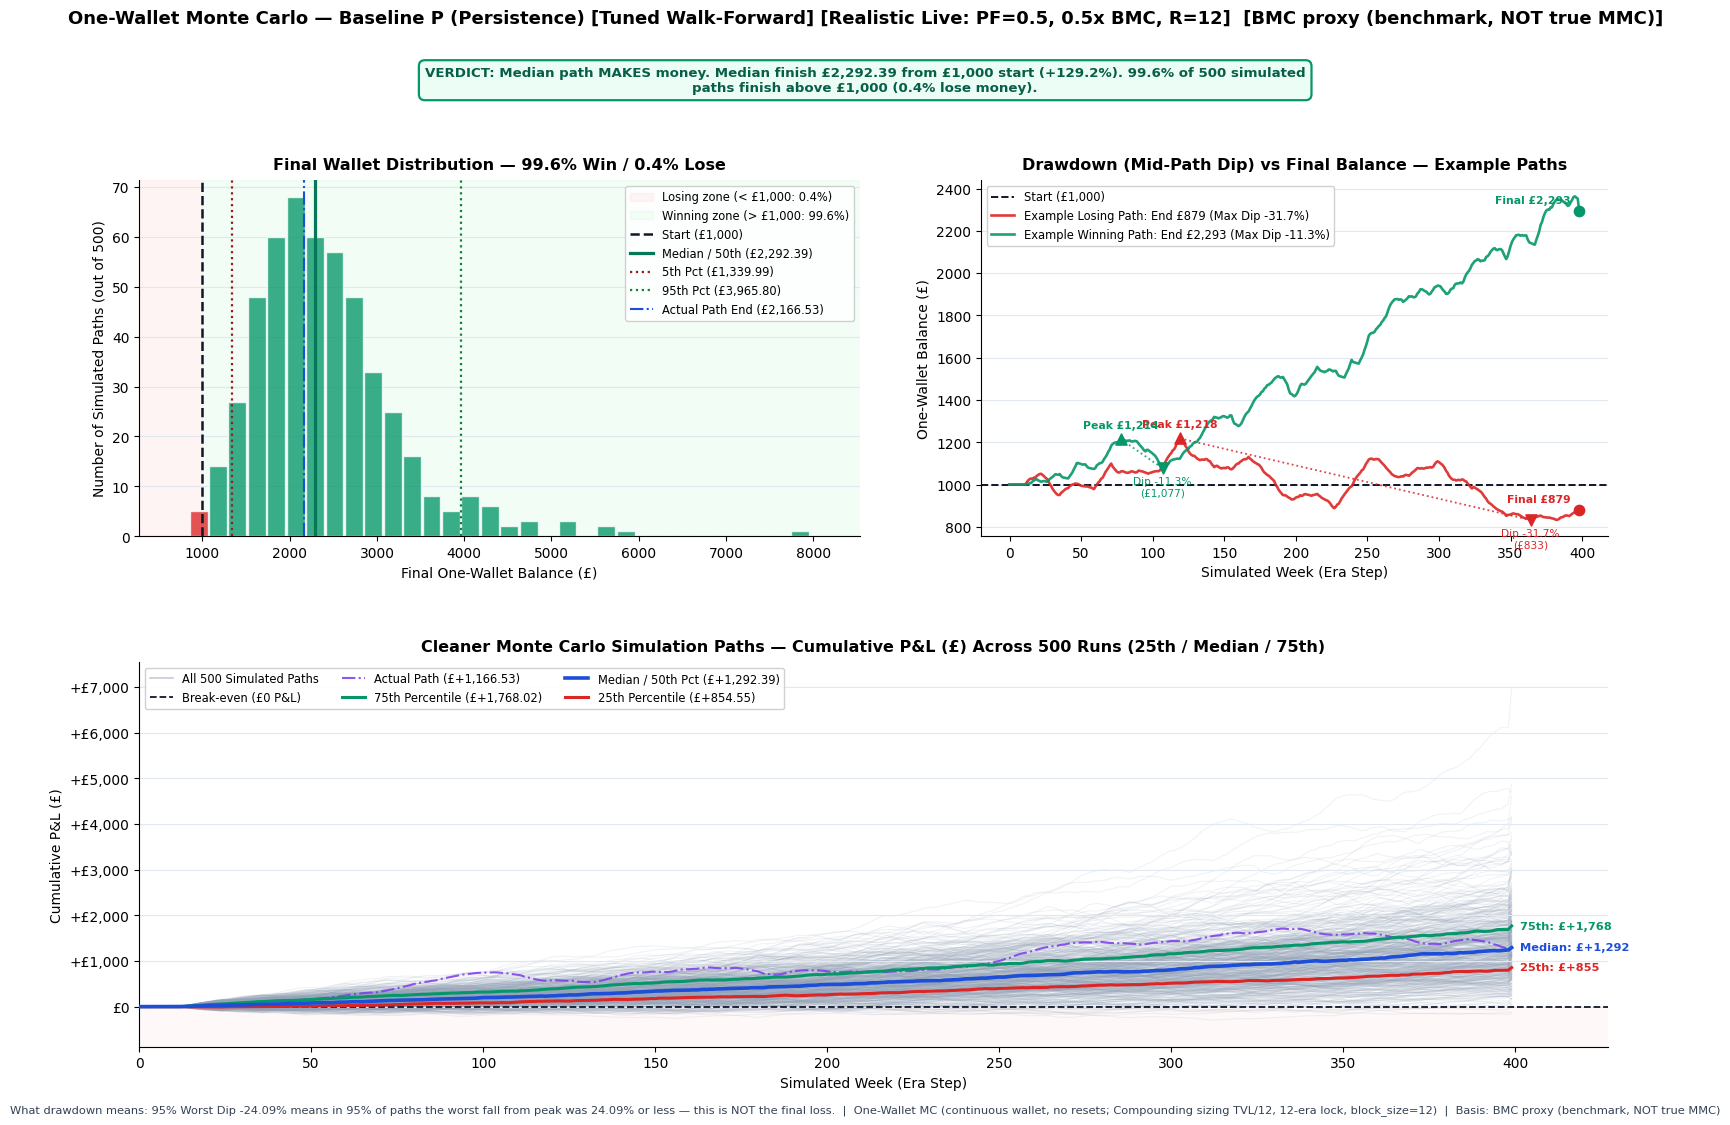

Baseline P (Persistence) [Tuned Walk-Forward] — VERDICT: Median path MAKES money. Median finish £2,292.39 from £1,000 start (+129.2%). 99.6% of 500 simulated paths finish above £1,000 (0.4% lose money).

Baseline P (Persistence) [Tuned Walk-Forward] [Realistic Live: PF=0.5, 0.5x BMC, R=12] [One-Wallet MC | BMC proxy (benchmark, NOT true MMC) | Compounding] | P(Profit): 99.6% (0.4% lose) | Median (50th): £2,292.39 (+129.2%) | 5th Pct: £1,339.99 | 95th Pct: £3,965.80 | 95% Worst Dip: -24.09% | P(Ruin): 0.0%
  -> What drawdown means: 95% Worst Dip -24.09% means in 95% of paths the worst fall from peak was 24.09% or less — this is NOT the final loss.
  -> Conservative Floor MC (CORR only, PF=0.5, R=12): P(Profit)=99.6% | Median=£1,348.30 | 95% Worst Dip=-7.22%


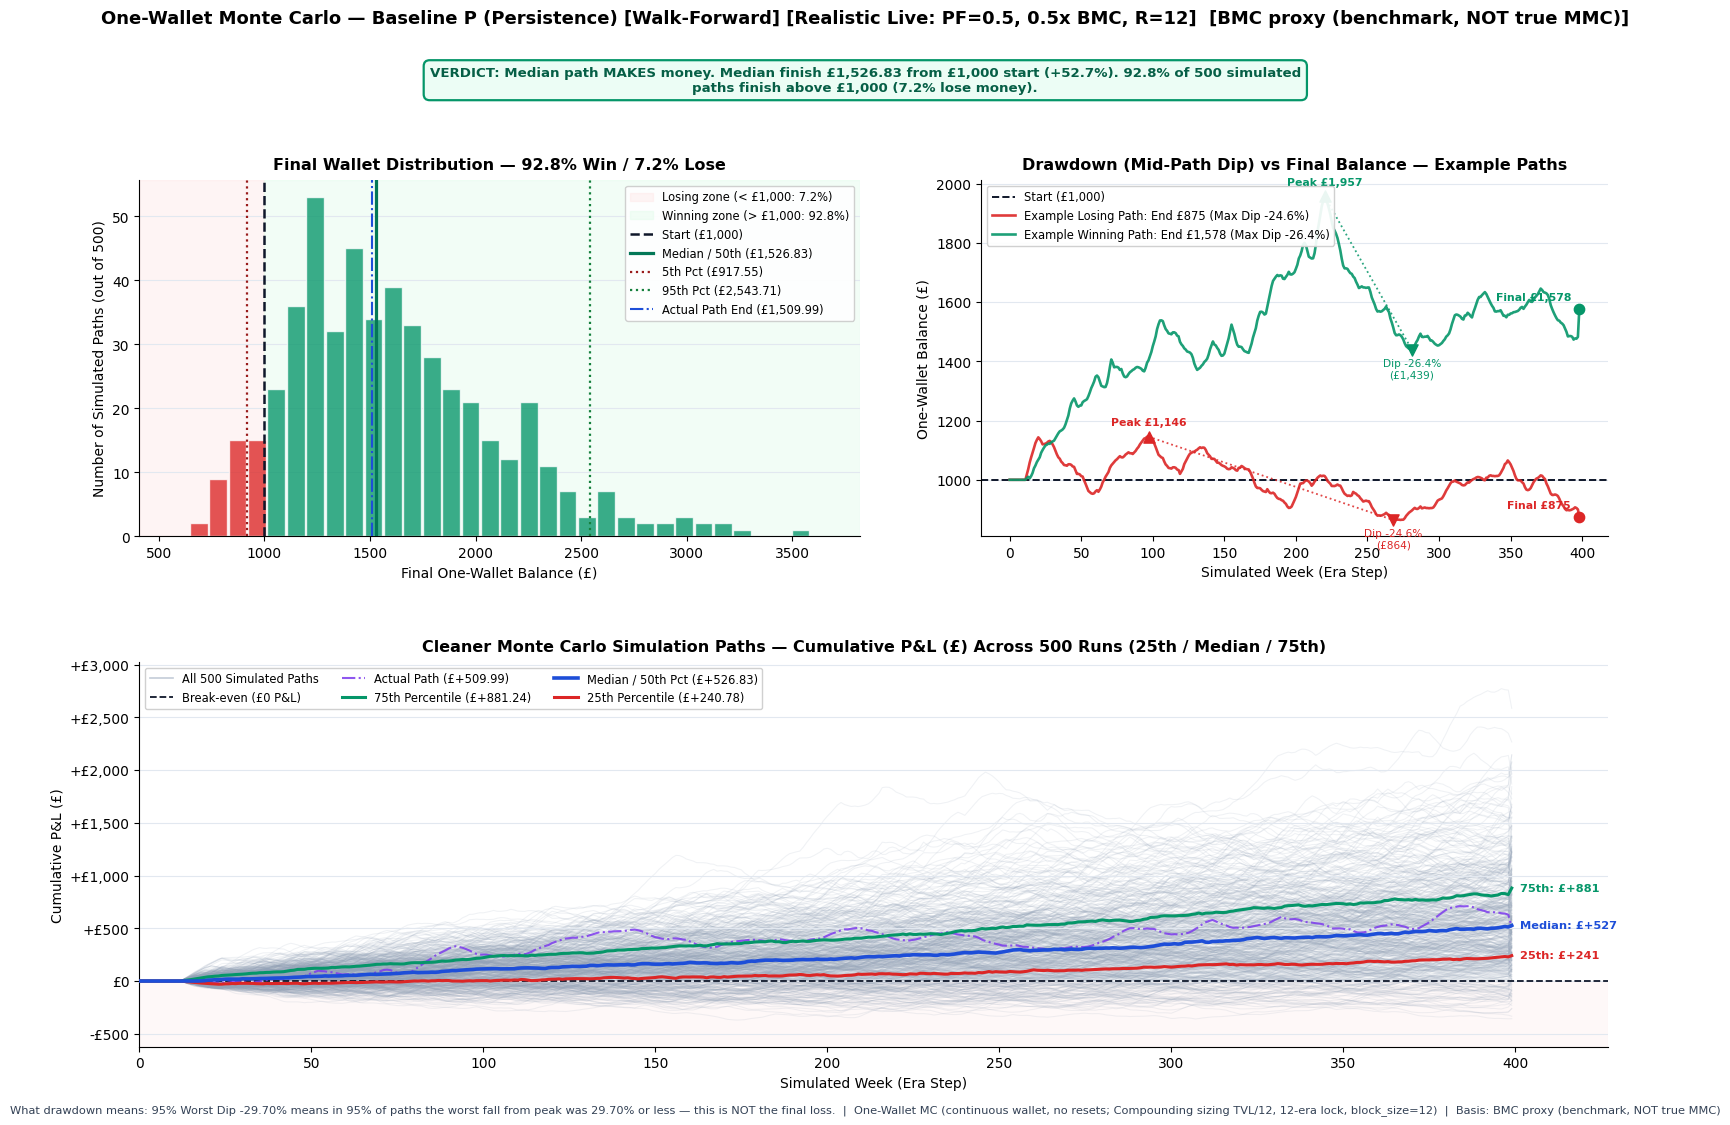

Baseline P (Persistence) [Walk-Forward] — VERDICT: Median path MAKES money. Median finish £1,526.83 from £1,000 start (+52.7%). 92.8% of 500 simulated paths finish above £1,000 (7.2% lose money).

Baseline P (Persistence) [Walk-Forward] [Realistic Live: PF=0.5, 0.5x BMC, R=12] [One-Wallet MC | BMC proxy (benchmark, NOT true MMC) | Compounding] | P(Profit): 92.8% (7.2% lose) | Median (50th): £1,526.83 (+52.7%) | 5th Pct: £917.55 | 95th Pct: £2,543.71 | 95% Worst Dip: -29.70% | P(Ruin): 0.0%
  -> What drawdown means: 95% Worst Dip -29.70% means in 95% of paths the worst fall from peak was 29.70% or less — this is NOT the final loss.
  -> Conservative Floor MC (CORR only, PF=0.5, R=12): P(Profit)=61.0% | Median=£1,029.87 | 95% Worst Dip=-19.00%


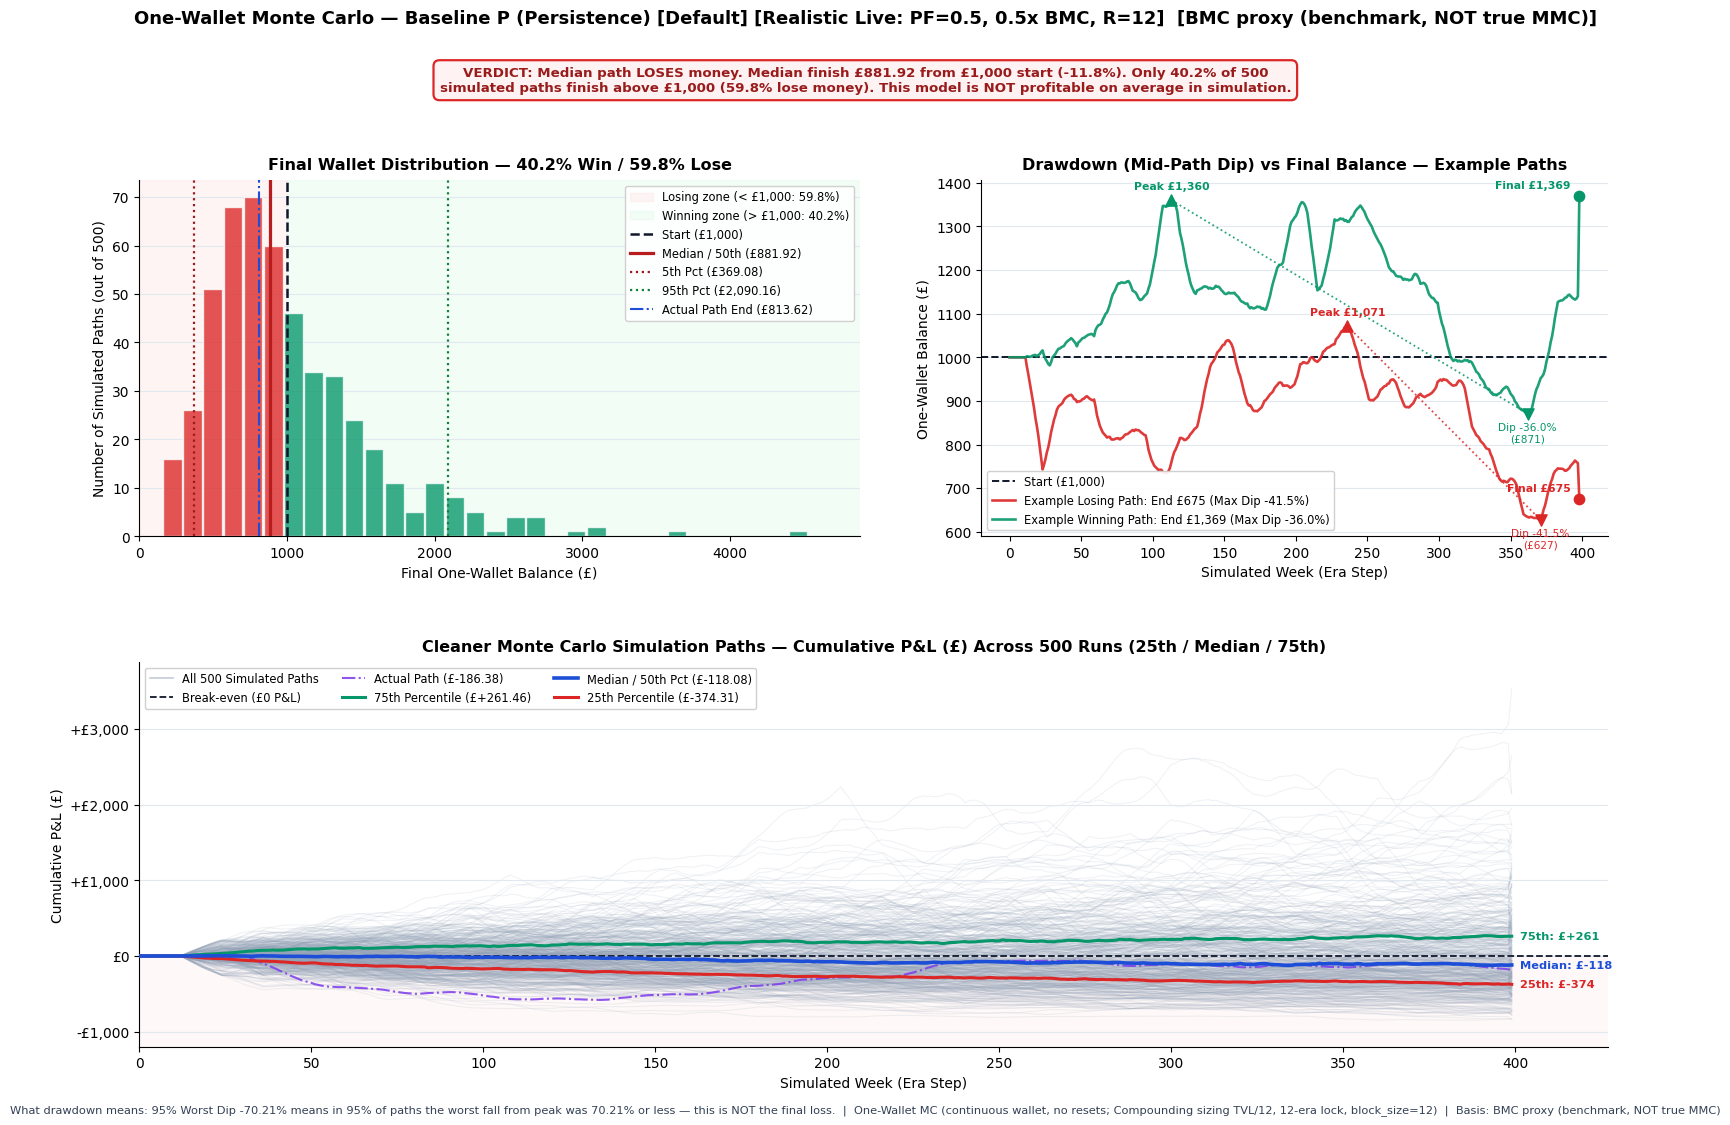

Baseline P (Persistence) [Default] — VERDICT: Median path LOSES money. Median finish £881.92 from £1,000 start (-11.8%). Only 40.2% of 500 simulated paths finish above £1,000 (59.8% lose money). This model is NOT profitable on average in simulation.

Baseline P (Persistence) [Default] [Realistic Live: PF=0.5, 0.5x BMC, R=12] [One-Wallet MC | BMC proxy (benchmark, NOT true MMC) | Compounding] | P(Profit): 40.2% (59.8% lose) | Median (50th): £881.92 (-11.8%) | 5th Pct: £369.08 | 95th Pct: £2,090.16 | 95% Worst Dip: -70.21% | P(Ruin): 0.0%
  -> What drawdown means: 95% Worst Dip -70.21% means in 95% of paths the worst fall from peak was 70.21% or less — this is NOT the final loss.
  -> Conservative Floor MC (CORR only, PF=0.5, R=12): P(Profit)=46.0% | Median=£979.00 | 95% Worst Dip=-31.28%


46431

In [15]:
mc_risk_by_variant = {}
explainer_printed = False
staking_is_proxy = bool(v6_contrib_info['mmc_is_proxy'])
for variant_name in comparison_df['variant'].tolist():
    is_best_variant = (variant_name == best_variant_name)
    variant_slug = (
        variant_name.lower()
        .replace(' ', '_')
        .replace('(', '')
        .replace(')', '')
        .replace('[', '')
        .replace(']', '')
        .replace('-', '_')
    )
    mc_save_path = (
        results_dir / f'{timestamp}_{experiment_name}_{variant_slug}_monte_carlo_pnl.png'
        if save_results
        else None
    )
    title_label = f'[CV-LOCKED WINNER] {variant_name}' if is_best_variant else variant_name
    raw_contrib = variant_era_mmc_by_variant.get(variant_name)
    haircutted_contrib = (
        pd.Series(raw_contrib, dtype=np.float64) * (0.5 if staking_is_proxy else 1.0)
        if raw_contrib is not None
        else None
    )
    if haircutted_contrib is not None:
        haircutted_contrib.name = 'bmc_proxy' if staking_is_proxy else 'mmc'
    v_mc = plot_stake_pnl_monte_carlo(
        baseline_results[variant_name]['validation_era_corrs'],
        per_era_mmc=haircutted_contrib,
        mmc_is_proxy=staking_is_proxy,
        title=f'{title_label} [Realistic Live: PF=0.5, 0.5x BMC, R=12]',
        total_capital=1000.0,
        concurrent_rounds=12,
        settlement_rounds=12,
        payout_factor=0.5,
        payout_rule='auto',
        staking_mode='compound',
        n_sims=500,
        block_size=12,
        random_state=random_state,
        era_dates=val_era_dates,
        save_path=mc_save_path,
        retain_paths=False,
    )
    mc_risk_by_variant[variant_name] = v_mc
    c_mc = live_scenarios_by_variant[variant_name]['conservative_floor']['mc']
    print('=' * 100)
    print(f"{title_label} — {v_mc['mc_verdict_text']}")
    if not explainer_printed:
        print()
        print(v_mc['mc_explainer_text'])
        explainer_printed = True
    print()
    print(v_mc['mc_summary_line'])
    print(f"  -> {v_mc['mc_drawdown_explanation_line']}")
    print(
        f"  -> Conservative Floor MC (CORR only, PF=0.5, R=12): P(Profit)={c_mc['mc_prob_profit_pct']:.1f}% | "
        f"Median=£{c_mc['mc_median_final_stake']:,.2f} | 95% Worst Dip={c_mc['mc_p95_money_drawdown_pct']:.2f}%"
    )
    print('=' * 100)
gc.collect()

### Cumulative & Rolling 20-Era Validation CORR

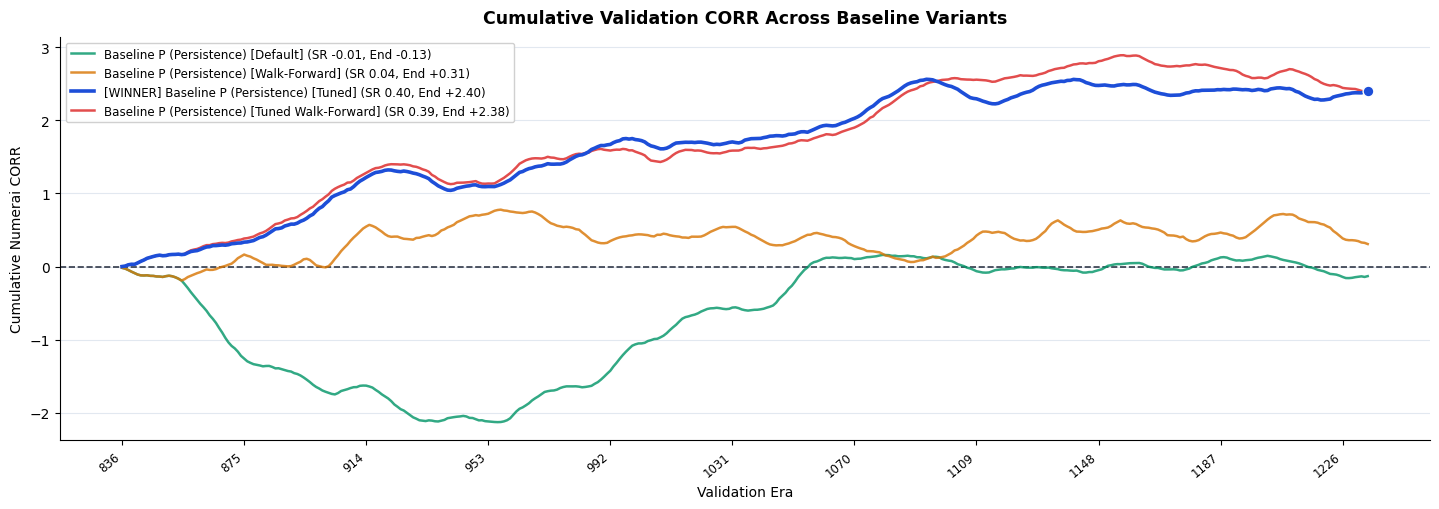

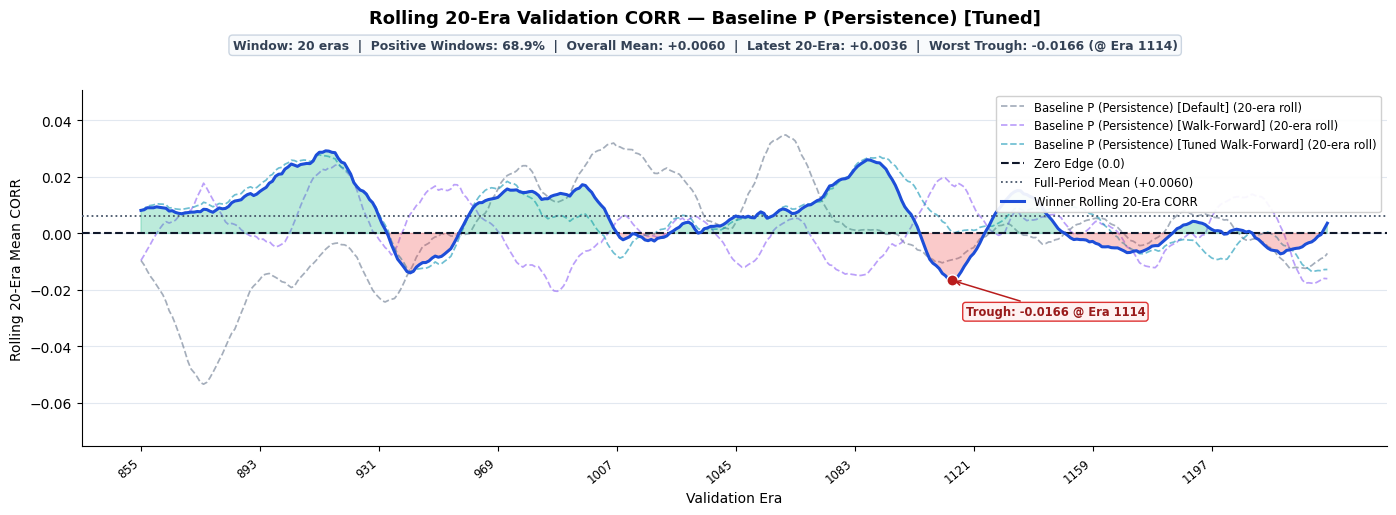

In [16]:
cum_corr_save_path = (
    results_dir / f'{timestamp}_{experiment_name}_cumulative_validation_corr.png'
    if save_results
    else None
)
cumulative_corr_df = plot_cumulative_validation_corr(
    baseline_results,
    best_variant_name=best_variant_name,
    title='Cumulative Validation CORR Across Baseline Variants',
    save_path=cum_corr_save_path,
)

secondary_era_corrs = {
    v_name: v_res['validation_era_corrs']
    for v_name, v_res in baseline_results.items()
    if v_name != best_variant_name
}
rolling_corr_save_path = (
    results_dir / f'{timestamp}_{experiment_name}_rolling_20era_validation_corr.png'
    if save_results
    else None
)
rolling_20era_corr = plot_rolling_validation_corr(
    best_validation_era_corrs,
    window=20,
    comparison_corrs=secondary_era_corrs,
    title=f'Rolling 20-Era Validation CORR — {best_variant_name}',
    save_path=rolling_corr_save_path,
)

## Model Diagnostics & Residual Visuals
Compact feature-neutral & error diagnostics table, peak-annotated error-direction envelope, side-by-side Top-2 variants Residuals vs. Actual plot, and model-specific interpretability.

### Compact Diagnostics Table

In [17]:
diagnostics_table_df = build_diagnostics_summary_table(
    comparison_df,
    best_variant_name=best_variant_name,
)
display_compact_dataframe(
    diagnostics_table_df,
    title='Model Diagnostics Table (Feature Exposure, FNC, MAE, Forecast Bias & Hit Rate):',
)

Model Diagnostics Table (Feature Exposure, FNC, MAE, Forecast Bias & Hit Rate):


,variant,feature_exposure,validation_fnc,validation_fnc_sharpe,validation_mae,forecast_bias,directional_hit_rate
0,[WINNER] Baseline P (Persistence) [Tuned],NaN,NaN,NaN,0.1539,-0.0018,0.5050
1,Baseline P (Persistence) [Tuned Walk-Forward],NaN,NaN,NaN,0.1548,-0.0020,0.5042
2,Baseline P (Persistence) [Walk-Forward],NaN,NaN,NaN,0.2195,-0.0004,0.2996
3,Baseline P (Persistence) [Default],NaN,NaN,NaN,0.2078,-0.0008,0.3169


### Error-Direction Envelope Analysis

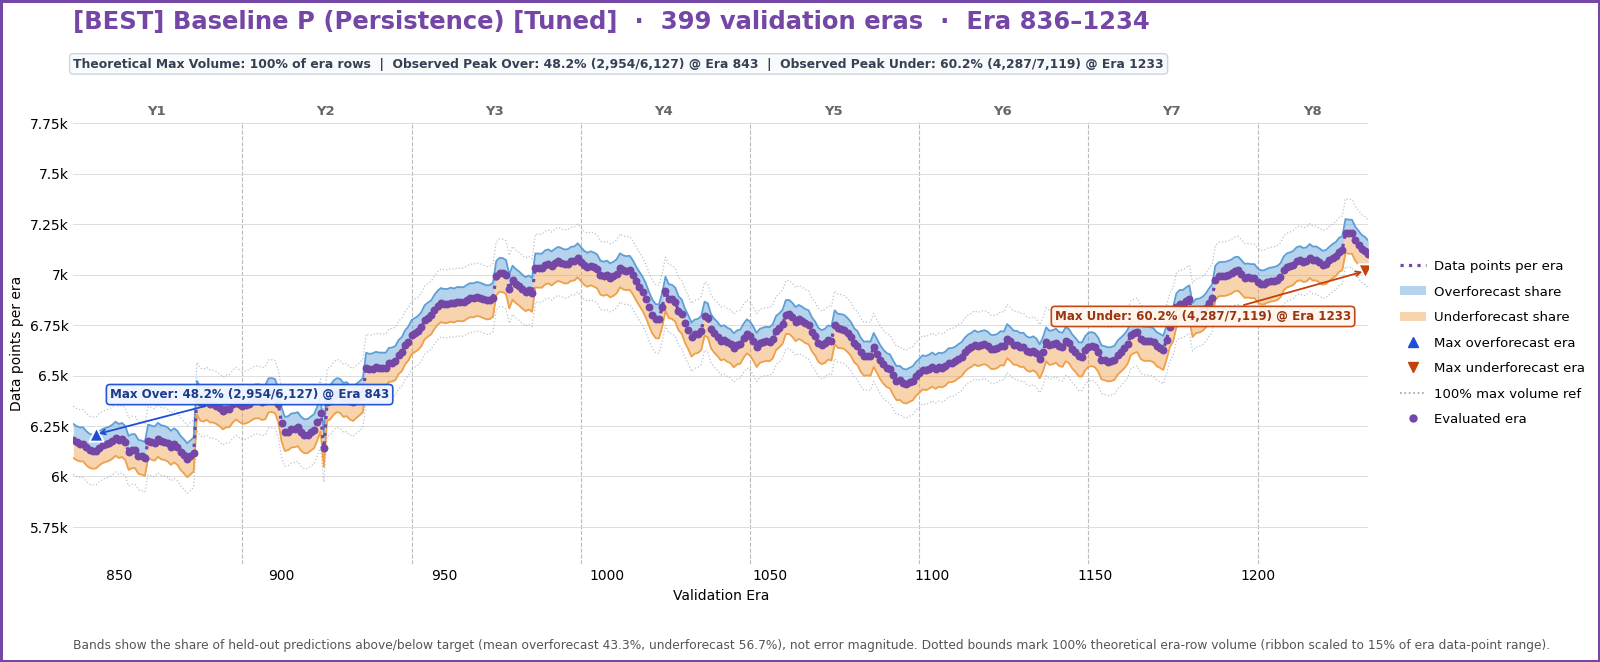

Best Model Envelope Summary (Baseline P (Persistence) [Tuned]):


,data_points,under_share,over_share,under_count,over_count,mae,mean_residual,is_interpolated
era,,,,,,,,
836,6180,0.525566,0.474434,3248,2932,0.154942,0.001838,False
837,6169,0.522775,0.477225,3225,2944,0.154811,0.001843,False
838,6163,0.525393,0.474607,3238,2925,0.154859,0.001864,False
839,6163,0.522473,0.477527,3220,2943,0.154861,0.001877,False
840,6144,0.523438,0.476562,3216,2928,0.154926,0.001897,False
841,6130,0.520065,0.479935,3188,2942,0.154678,0.001920,False
842,6126,0.519915,0.480085,3185,2941,0.154674,0.001917,False
843,6127,0.517872,0.482128,3173,2954,0.154827,0.001905,False
844,6143,0.522383,0.477617,3209,2934,0.154719,0.001874,False


In [18]:
envelope_dfs = {}
seen_model_families = set()
envelope_variants = []
ordered_envelope_candidates = [best_variant_name] + [
    variant_name for variant_name in comparison_df['variant'].tolist() if variant_name != best_variant_name
]
for variant_name in ordered_envelope_candidates:
    if variant_name not in baseline_results:
        continue
    model_family = variant_name.split(' [')[0]
    if model_family not in seen_model_families:
        seen_model_families.add(model_family)
        envelope_variants.append(variant_name)

for variant_name in envelope_variants:
    is_best_variant = (variant_name == best_variant_name)
    variant_slug = (
        variant_name.lower()
        .replace(' ', '_')
        .replace('(', '')
        .replace(')', '')
        .replace('[', '')
        .replace(']', '')
        .replace('-', '_')
    )
    envelope_save_path = (
        results_dir / f'{timestamp}_{experiment_name}_{variant_slug}_error_envelope.png'
        if save_results
        else None
    )
    envelope_dfs[variant_name] = plot_era_error_envelope(
        y_validation,
        baseline_results[variant_name]['validation_preds'],
        validation_eras,
        title=variant_name,
        band_size=0.15,
        is_best=is_best_variant,
        save_path=envelope_save_path,
    )

envelope_df = envelope_dfs[best_variant_name]
display_compact_dataframe(
    envelope_df.head(10),
    title=f'Best Model Envelope Summary ({best_variant_name}):',
)

### Top-2 Variants Residuals vs. Actual

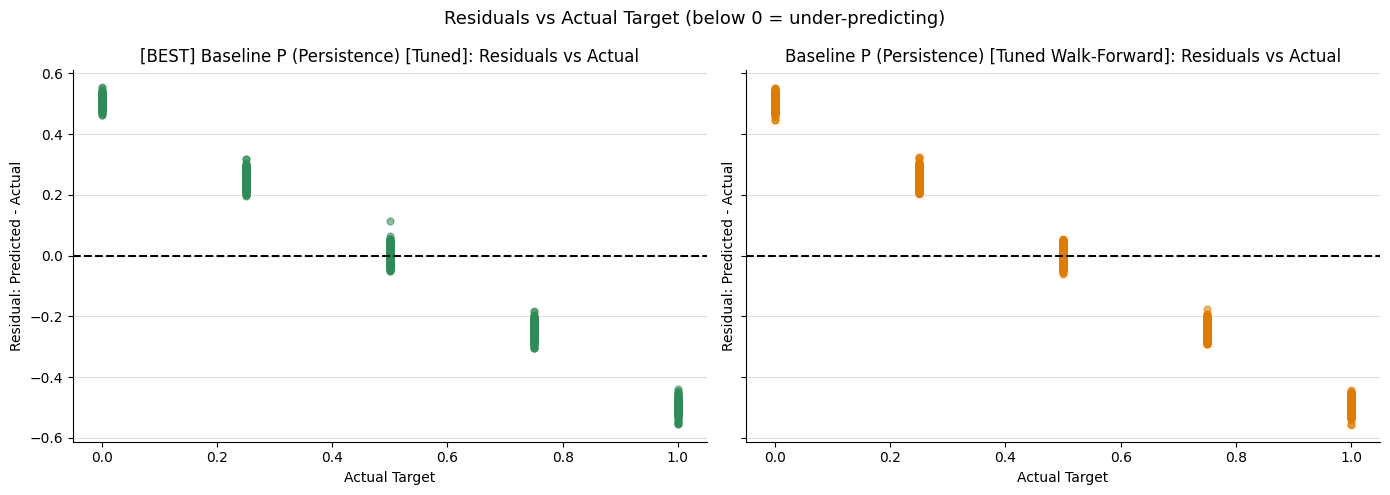

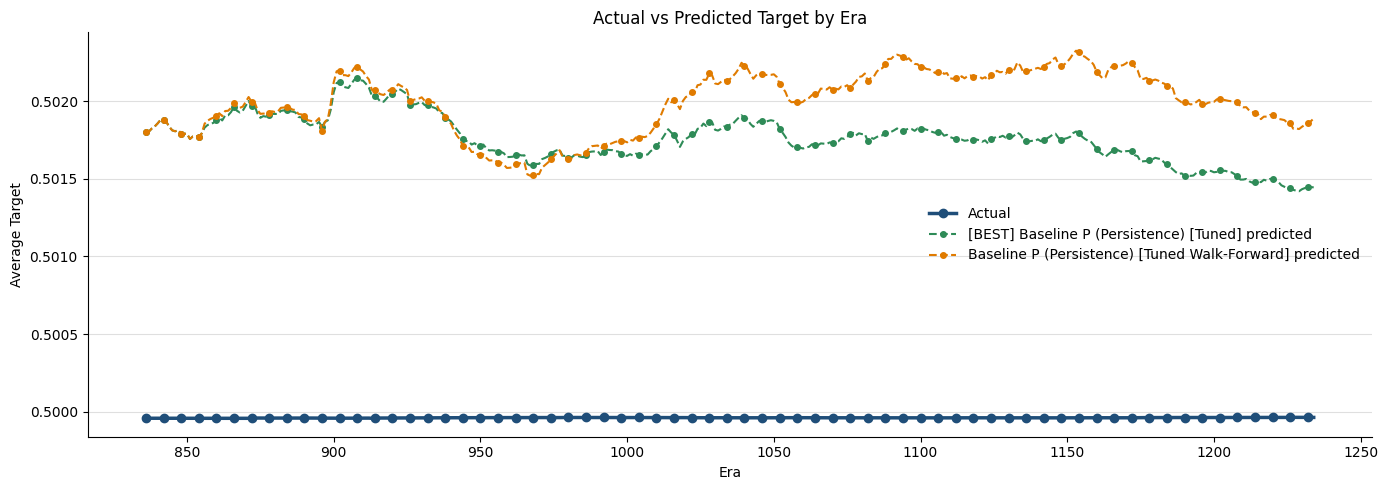

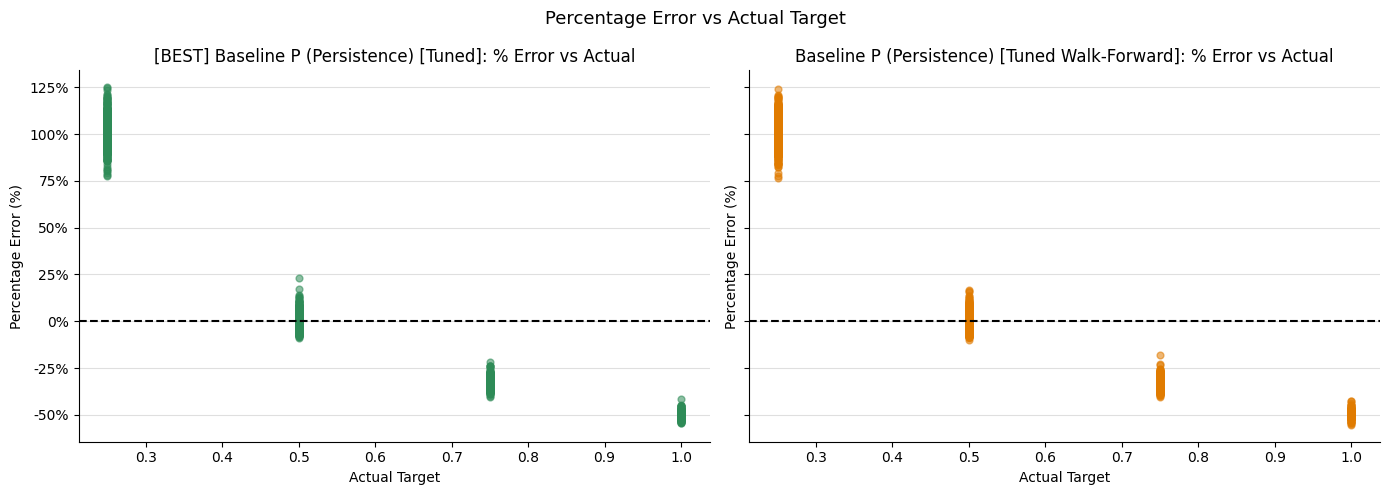

Top-2 Variants Residual Diagnostics Summary:


,variant,n_valid,mean_residual,mae,rmse,under_predict_pct,over_predict_pct
0,[BEST] Baseline P (Persistence) [Tuned],2660746,0.001792,0.1539,0.2240,56.78,43.22
1,Baseline P (Persistence) [Tuned Walk-Forward],2660746,0.002028,0.1548,0.2241,53.27,46.73


0

In [19]:
resid_diag_save_prefix = (
    results_dir / f'{timestamp}_{experiment_name}_residual_diagnostics'
    if save_results
    else None
)
residual_diag_summary_df = plot_residual_diagnostics(
    y_validation,
    baseline_results,
    validation_eras,
    best_variant_name=best_variant_name,
    variant_order=comparison_df['variant'].tolist(),
    max_models=2,
    random_state=random_state,
    save_prefix=resid_diag_save_prefix,
)
display_compact_dataframe(
    residual_diag_summary_df,
    title='Top-2 Variants Residual Diagnostics Summary:',
)

numereval_summary_df = run_numereval_diagnostics(
    y_validation,
    baseline_results[best_variant_name]['validation_preds'],
    validation_eras,
    variant_name=best_variant_name,
    plot=False,
    verbose=False,
)
strip_validation_predictions(baseline_results)
del y_validation, validation_eras
gc.collect()

### Model Interpretability & Top CV Candidates

In [20]:
display_baseline_interpretability(
    baseline_interpretability,
    results_dir=results_dir,
    timestamp=timestamp,
    experiment_name=experiment_name,
    save_results=save_results,
)

Baseline P (Persistence) | mode=expanding_mean | lag=12 | global_mean=0.4999 | tracked_tickers=13662


,ticker,persisted_target,obs_count,last_era
0,000270 KR,0.485517,69,817
1,000810 KR,0.496143,69,817
2,003490 KR,0.492049,69,817
3,004170 KR,0.491254,69,817
4,005380 KR,0.504227,69,817
5,005490 KR,0.504215,69,817
6,005930 KR,0.522264,69,817
7,005940 KR,0.501729,69,817
8,006360 KR,0.491477,69,817
9,006400 KR,0.551533,69,817


In [21]:
display_top_cv_candidates(cv_analysis_artifacts)

Top CV candidates for Baseline P (Persistence):


,candidate_id,rank_test_score,mean_test_score,score_version,end_capital,total_profit,total_return_pct,money_drawdown_pct,mean_directional_accuracy_pct,mean_accurate_pct,mean_numerai_corr,mean_sharpe,mean_positive_era_pct,mean_era_consistency_pct,mean_corr_drawdown,mean_mae,mean_fit_time,std_fit_time,mean_score_time,std_score_time,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,split5_test_score,split6_test_score,split7_test_score,split8_test_score,split9_test_score,split10_test_score,split11_test_score,split12_test_score,split13_test_score,split14_test_score,split15_test_score,split16_test_score,split17_test_score,split18_test_score,split19_test_score,split20_test_score,split21_test_score,split22_test_score,split23_test_score,split24_test_score,split25_test_score,split26_test_score,split27_test_score,split28_test_score,split29_test_score,split30_test_score,split31_test_score,split32_test_score,split33_test_score,split34_test_score,split35_test_score,split36_test_score,split37_test_score,split38_test_score,split39_test_score,split40_test_score,split41_test_score,split42_test_score,split43_test_score,split44_test_score,split45_test_score,split46_test_score,split47_test_score,split48_test_score,split49_test_score,split50_test_score,split51_test_score,split52_test_score,split53_test_score,split54_test_score,split55_test_score,split56_test_score,split57_test_score,split58_test_score,split59_test_score,split60_test_score,split61_test_score,split62_test_score,split63_test_score,split64_test_score,split65_test_score,split66_test_score,split67_test_score,split68_test_score,std_test_score,mean_test_score_pct,mean_era_corr_std,mean_underforecast_pct,mean_extreme_underforecast_pct,mean_overforecast_pct,mean_extreme_overforecast_pct,mean_spearman,mean_forecast_bias,start_capital,max_drawdown_gbp,worst_round_gbp,bias_correction,era_weighting,persistence_mode,prediction_transform,recency_decay,smoothing,walk_forward_step_eras,walk_forward_window
0,0,1,0.003028,v1_skepta,1009.8,9.8,0.98,-0.55,50.13,46.54,0.003,0.0,60.87,53.62,0.0057,0.1543,0.292977,0.122189,0.386141,0.130211,-0.014461,-0.041317,-0.017058,0.008693,0.000191,-0.024763,0.029559,0.046131,0.005682,0.011491,0.017052,0.007132,-0.003012,-0.015883,0.000001,-0.011672,0.028983,0.025284,-0.003763,0.037107,-0.006682,0.007413,0.007239,-0.011899,0.015258,0.03151,0.007214,-0.006282,0.017832,-0.019,-0.00369,0.026048,0.003289,-0.015547,0.027838,0.027699,0.01912,-0.032183,0.000005,-0.004672,0.014554,0.000765,0.006533,-0.033171,-0.036421,0.00452,-0.011998,-0.020689,0.01026,-0.015885,0.013428,0.032091,-0.01229,0.004089,-0.009198,0.005824,-0.001578,-0.001024,0.003497,0.000141,0.01249,-0.002791,0.026965,0.024808,0.012673,0.007087,0.009034,0.005948,-0.016601,0.018055,0.3,0.0,1.45,25.05,1.82,25.14,0.0031,-0.001,1000.0,-5.59,-1.94,None,uniqueness,expanding_mean,None,0.013733,41.411863,20,sliding


Saved CV results CSV: /kaggle/working/results_numerai_v6.0_all_eras_stride12_baselines_ae_target_bayes/20261125_234137_numerai_v6.0_all_eras_stride12_baselines_ae_persistence_bayes_cv.csv


## AFML Backtest Visual Story
2×2 statistical credibility dashboard for the Train-CV-Locked Winner (**PSR/DSR vs. 95%**, **Observed Eras vs. MinTRL**, **Underwater / Time-Underwater Curve**, and **HHI Concentration & Regime Health**) followed by the compact AFML reference table.

### Statistical Credibility & Regime Dashboard

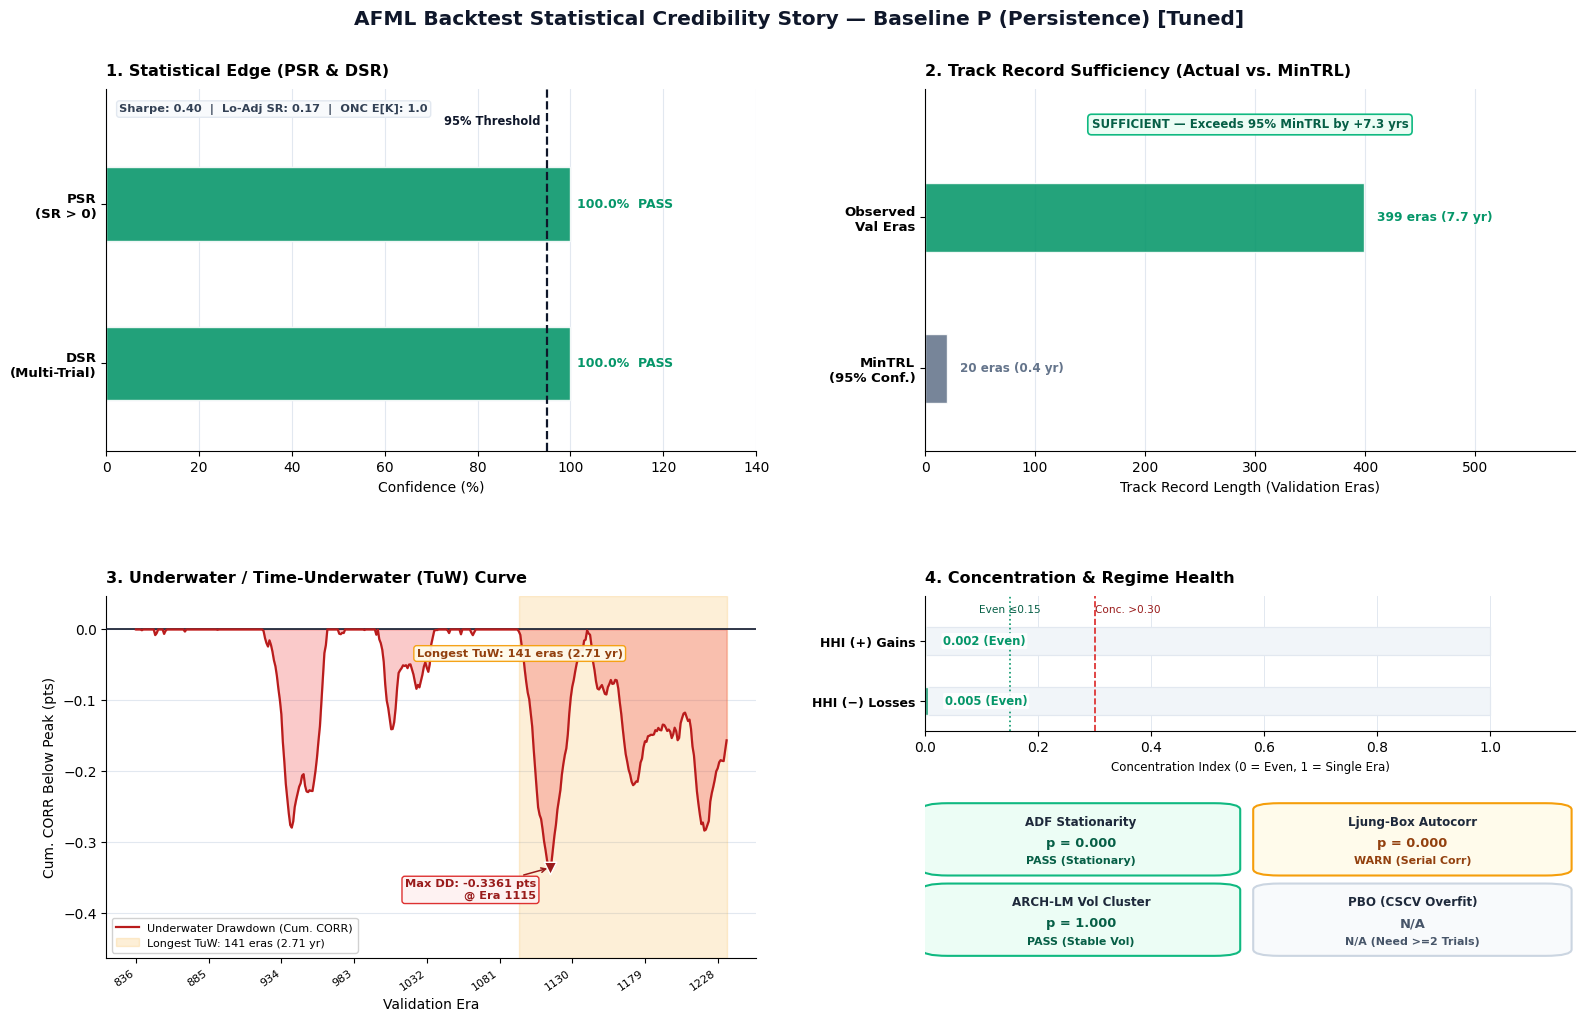

In [22]:
afml_diagnostics_df = build_afml_diagnostics_df(
    baseline_results,
    cv_trial_stats_by_baseline=cv_analysis_artifacts['trial_stats'],
    random_state=random_state,
)

winner_afml_matches = afml_diagnostics_df.loc[afml_diagnostics_df['variant'].astype(str) == str(best_variant_name)]
winner_afml_row = (
    winner_afml_matches.reset_index(drop=True).loc[0].to_dict()
    if not winner_afml_matches.empty
    else afml_diagnostics_df.reset_index(drop=True).loc[0].to_dict()
)
afml_story_save_path = (
    results_dir / f'{timestamp}_{experiment_name}_afml_backtest_story.png'
    if save_results
    else None
)
afml_story_summary = plot_afml_backtest_story(
    best_validation_era_corrs,
    winner_afml_row,
    regime_stats=baseline_results[best_variant_name],
    title=best_variant_name,
    save_path=afml_story_save_path,
)

### AFML Backtest Reference Table

In [23]:
compact_afml_df = build_compact_afml_reference_table(
    afml_diagnostics_df,
    best_variant_name=best_variant_name,
)
display_compact_dataframe(
    compact_afml_df,
    title='AFML Backtest Credibility Reference Table (PSR, DSR, MinTRL, PBO, TuW & HHI):',
)
if save_results:
    results_dir.mkdir(parents=True, exist_ok=True)
    afml_diagnostics_df.to_csv(results_dir / f'{timestamp}_{experiment_name}_afml_diagnostics.csv', index=False)

AFML Backtest Credibility Reference Table (PSR, DSR, MinTRL, PBO, TuW & HHI):


,variant,n_eras,numerai_sharpe,lo_adjusted_sharpe,psr,dsr,min_trl_years,pbo_cscv,tuw_max_years,hhi_pos,hhi_neg,strategy_fail_prob
0,[WINNER] Baseline P (Persistence) [Tuned],399,0.404,0.173,1.0000,1.0000,0.37,NaN,2.71,0.0019,0.0049,0.0000
1,Baseline P (Persistence) [Default],399,-0.015,-0.006,0.3835,0.3835,inf,NaN,4.23,0.0044,0.0044,0.9992
2,Baseline P (Persistence) [Walk-Forward],399,0.039,0.018,0.7824,0.7824,34.04,NaN,5.33,0.0028,0.0022,0.9657
3,Baseline P (Persistence) [Tuned Walk-Forward],399,0.391,0.167,1.0000,1.0000,0.40,NaN,1.50,0.0018,0.0050,0.0000


## Optional Community Companion: `numereval` (Council of Elders)
Runs `councilofelders/numereval` alongside official `numerai-tools` metrics when installed locally (skips gracefully on Kaggle if unavailable). **Note:** `numereval` uses classic Spearman diagnostics and is not the official v6.0 Unity `NCORR` / `NMMC` / staking calculation.

In [24]:
if numereval_summary_df is not None:
    print(
        f"[numereval companion — {best_variant_name}] Community Spearman diagnostics "
        "(informational alongside official numerai_tools v6.0 metrics; NOT official v6.0 NCORR/NMMC):"
    )
    display_compact_dataframe(numereval_summary_df)
else:
    run_numereval_diagnostics([], [], [], variant_name=best_variant_name, plot=False, verbose=True)

[numereval companion — Baseline P (Persistence) [Tuned]] Community Spearman diagnostics (informational alongside official numerai_tools v6.0 metrics; NOT official v6.0 NCORR/NMMC):


,metrics
mean,0.0062
std,0.0130
sharpe,0.4760
max_drawdown,-2.6308
